# Decision Trees using Python — Learn It, Then Prove It
### Classification, Regression, Model Trees and Pruning on the UCI Bank Marketing Dataset

**B.Tech Semester VII · Artificial Intelligence (20CST401) · Module V — Assignment 3 (Infosys Springboard, Roll no. 51–75)**

## 1. Title

**Decision Trees using Python: evidence for the nine learning outcomes of the Infosys Springboard course, demonstrated on the Bank Marketing (with social/economic context) dataset.**

## 2. Student Details

| Field | Details |
|---|---|
| Name | *(fill in)* |
| Roll number | **70** |
| Programme / Semester | B.Tech, Semester VII |
| Course | Artificial Intelligence (20CST401) — Module V, Machine Learning |
| Assignment | Assignment 3 — *Learn It, Then Prove It* (Infosys Springboard, Roll no. 51–75) |
| Springboard course | "Decision Trees using Python" (Infosys Springboard / Wingspan) |
| Springboard course link | *(paste the exact URL from your logged-in Springboard session)* |
| Completion certificate | *(attach screenshot + certificate separately — Part A of the assignment)* |

## 3. Assignment Objective

The assignment requires **concrete evidence from my own code and output** for each of the nine learning outcomes of the course:

| # | Learning outcome |
|---|---|
| 1 | Induct a decision tree to perform classification. |
| 2 | Explain the attribute selection measures used to split the data for classification. |
| 3 | Predict the value of the outcome variable using the created decision tree model. |
| 4 | Evaluate the prediction accuracy of the decision tree. |
| 5 | Induct a decision tree to perform regression. |
| 6 | Explain the attribute selection measure used to split the data for regression. |
| 7 | Evaluate the regression tree using R-Squared and RMSE. |
| 8 | Induct model decision trees that fit piece-wise models after making decision splits. |
| 9 | Prune a decision tree by applying various stopping/pruning techniques. |

Every outcome is demonstrated with real code run on the real dataset in the `data/` folder; Section 17 maps each outcome to the exact cell/output that proves it.

## 4. Dataset Description

**Source:** *Bank Marketing (with social/economic context)*, UCI Machine Learning Repository — S. Moro, P. Cortez and P. Rita, "A Data-Driven Approach to Predict the Success of Bank Telemarketing", *Decision Support Systems*, 2014.

The data comes from direct-marketing **phone campaigns of a Portuguese bank** (May 2008 – Nov 2010). Each row is one client contact. The business question is: **will the client subscribe to a term deposit (`y` = yes/no)?**

**Files in `data/`** (verified in Section 5):

| File | What it is |
|---|---|
| `bank-additional-full.csv` | All 41,188 contacts, 20 inputs + target `y` |
| `bank-additional.csv` | A **10% random sample (4,119 rows)** of the full file — same columns |
| `bank-additional-names.txt` | The official data dictionary (used for the table below) |
| `.DS_Store`, `.Rhistory` | macOS folder metadata and an R command history from the original archive — **not data**, ignored |

**Which file I use and why:** the main notebook uses **`bank-additional.csv`**. The dataset documentation says this 10% sample was provided for computationally heavier experiments. It keeps every column and almost the same class balance as the full file (checked below), it is large enough for trees to learn meaningful patterns, and it keeps every cell fast — important because the pruning section trains hundreds of trees and uses cross-validation. The full file is only loaded once to confirm it has the same structure.

**Columns (from `bank-additional-names.txt`):**

| Group | Column | Type | Meaning |
|---|---|---|---|
| Client | `age` | numeric | age in years |
| Client | `job` | categorical | type of job |
| Client | `marital` | categorical | marital status ("divorced" includes widowed) |
| Client | `education` | categorical | education level |
| Client | `default` | categorical | has credit in default? |
| Client | `housing` | categorical | has a housing loan? |
| Client | `loan` | categorical | has a personal loan? |
| Last contact | `contact` | categorical | cellular / telephone |
| Last contact | `month`, `day_of_week` | categorical | when the last contact happened |
| Last contact | `duration` | numeric | **last call duration in seconds — only known after the call** (see leakage discussion) |
| Campaign | `campaign` | numeric | number of contacts in this campaign (including the last one) |
| Campaign | `pdays` | numeric | days since last contact in a previous campaign (**999 = never contacted**) |
| Campaign | `previous` | numeric | number of contacts before this campaign |
| Campaign | `poutcome` | categorical | outcome of the previous campaign |
| Economy | `emp.var.rate` | numeric | employment variation rate (quarterly) |
| Economy | `cons.price.idx` | numeric | consumer price index (monthly) |
| Economy | `cons.conf.idx` | numeric | consumer confidence index (monthly) |
| Economy | `euribor3m` | numeric | Euribor 3-month interest rate (daily) |
| Economy | `nr.employed` | numeric | number of employees in thousands (quarterly) |
| **Target** | **`y`** | binary | **has the client subscribed to a term deposit? (yes/no)** |

The documentation notes that missing values in categorical columns are coded as the label **`"unknown"`** rather than left blank.

## 5. Data Inspection

### 5.1 Imports and settings

In [1]:
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             r2_score, mean_squared_error)

RANDOM_STATE = 42          # fixed seed -> the same split and the same trees every run
DATA_DIR = "data"

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__)

pandas 3.0.3 | numpy 2.4.5 | scikit-learn 1.8.0


### 5.2 Files inside `data/`

In [2]:
for name in sorted(os.listdir(DATA_DIR)):
    size_kb = os.path.getsize(os.path.join(DATA_DIR, name)) / 1024
    print(f"{name:30s} {size_kb:10.1f} KB")

.DS_Store                             6.0 KB
.Rhistory                             3.9 KB
bank-additional-full.csv           5698.2 KB
bank-additional-names.txt             5.3 KB
bank-additional.csv                 570.2 KB


There are two CSV files. They are **semicolon-separated** (`;`), so `sep=";"` is required when reading them. Everything is read only — the original files are never modified.

In [3]:
df = pd.read_csv(os.path.join(DATA_DIR, "bank-additional.csv"), sep=";")
df_full = pd.read_csv(os.path.join(DATA_DIR, "bank-additional-full.csv"), sep=";")

print("bank-additional.csv      shape:", df.shape)
print("bank-additional-full.csv shape:", df_full.shape)
print("Same columns in both files?  ", list(df.columns) == list(df_full.columns))
print("\nShare of 'yes' in the sample file: {:.2%}".format((df["y"] == "yes").mean()))
print("Share of 'yes' in the full file:   {:.2%}".format((df_full["y"] == "yes").mean()))

bank-additional.csv      shape: (4119, 21)
bank-additional-full.csv shape: (41188, 21)
Same columns in both files?   True

Share of 'yes' in the sample file: 10.95%
Share of 'yes' in the full file:   11.27%


The sample file has the same 21 columns and practically the same class balance as the full file, so it is a fair representative. **From here on, `df` (the 4,119-row file) is the dataset used.**

### 5.3 Shape, column names and data types

In [4]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
print("\nColumn names:", list(df.columns))

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_unique": df.nunique(),
    "example_value": df.iloc[0],
})
overview

Rows: 4119 | Columns: 21

Column names: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'y']


,dtype,n_unique,example_value
age,int64,67,30
job,str,12,blue-collar
marital,str,4,married
education,str,8,basic.9y
default,str,3,no
housing,str,3,yes
loan,str,3,no
contact,str,2,cellular
month,str,10,may
day_of_week,str,5,fri


### 5.4 First five rows

In [5]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,30,blue-collar,married,basic.9y,no,yes,no,cellular,may,fri,487,2,999,0,nonexistent,-1.8,92.893,-46.2,1.313,5099.1,no
1,39,services,single,high.school,no,no,no,telephone,may,fri,346,4,999,0,nonexistent,1.1,93.994,-36.4,4.855,5191.0,no
2,25,services,married,high.school,no,yes,no,telephone,jun,wed,227,1,999,0,nonexistent,1.4,94.465,-41.8,4.962,5228.1,no
3,38,services,married,basic.9y,no,unknown,unknown,telephone,jun,fri,17,3,999,0,nonexistent,1.4,94.465,-41.8,4.959,5228.1,no
4,47,admin.,married,university.degree,no,yes,no,cellular,nov,mon,58,1,999,0,nonexistent,-0.1,93.200,-42.0,4.191,5195.8,no


### 5.5 Missing values and duplicates

Two kinds of "missing" must be checked: real blanks (`NaN`) and the dataset's own `"unknown"` code.

In [6]:
categorical_cols = df.select_dtypes(exclude="number").columns.drop("y").tolist()
numeric_cols = df.select_dtypes(include="number").columns.tolist()

missing = pd.DataFrame({
    "NaN_count": df.isna().sum(),
    "unknown_count": [(df[c] == "unknown").sum() if c in categorical_cols else 0 for c in df.columns],
})
missing["unknown_%"] = (100 * missing["unknown_count"] / len(df)).round(2)
print("Total NaN values in the whole table:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))
missing[missing["unknown_count"] > 0]

Total NaN values in the whole table: 0
Duplicate rows: 0


,NaN_count,unknown_count,unknown_%
job,0,39,0.95
marital,0,11,0.27
education,0,167,4.05
default,0,803,19.50
housing,0,105,2.55
loan,0,105,2.55


**Findings:** there are **no `NaN` values and no duplicate rows** in `bank-additional.csv`. Six categorical columns contain the label `"unknown"` — most notably `default` (almost 20% of rows). I keep `"unknown"` as **its own category**, which the documentation explicitly allows: "unknown" may itself carry information (e.g. a client who does not disclose their credit default status), and deleting those rows would throw away a fifth of the data.

### 5.6 Categorical columns — unique values

In [7]:
print("Categorical inputs:", categorical_cols)
print("Numerical inputs:  ", numeric_cols, "\n")
for col in categorical_cols + ["y"]:
    counts = df[col].value_counts()
    print(f"{col:12s} ({counts.size} levels): {dict(counts)}")

Categorical inputs: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numerical inputs:   ['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed'] 

job          (12 levels): {'admin.': np.int64(1012), 'blue-collar': np.int64(884), 'technician': np.int64(691), 'services': np.int64(393), 'management': np.int64(324), 'retired': np.int64(166), 'self-employed': np.int64(159), 'entrepreneur': np.int64(148), 'unemployed': np.int64(111), 'housemaid': np.int64(110), 'student': np.int64(82), 'unknown': np.int64(39)}
marital      (4 levels): {'married': np.int64(2509), 'single': np.int64(1153), 'divorced': np.int64(446), 'unknown': np.int64(11)}
education    (8 levels): {'university.degree': np.int64(1264), 'high.school': np.int64(921), 'basic.9y': np.int64(574), 'professional.course': np.int64(535), 'basic.4y': np.int64(429), 'basic.6y': np.int64(228), 'unknown':

### 5.7 Numerical summary statistics

In [8]:
df[numeric_cols].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
age,4119.0,40.114,10.313,18.000,32.000,38.000,47.000,88.000
duration,4119.0,256.788,254.704,0.000,103.000,181.000,317.000,3643.000
campaign,4119.0,2.537,2.568,1.000,1.000,2.000,3.000,35.000
pdays,4119.0,960.422,191.923,0.000,999.000,999.000,999.000,999.000
previous,4119.0,0.190,0.542,0.000,0.000,0.000,0.000,6.000
emp.var.rate,4119.0,0.085,1.563,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,4119.0,93.580,0.579,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,4119.0,-40.499,4.595,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,4119.0,3.621,1.734,0.635,1.334,4.857,4.961,5.045
nr.employed,4119.0,5166.482,73.668,4963.600,5099.100,5191.000,5228.100,5228.100


In [9]:
never_contacted = (df["pdays"] == 999).sum()
print(f"pdays == 999 (client never contacted before): {never_contacted} rows ({never_contacted / len(df):.1%})")

pdays == 999 (client never contacted before): 3959 rows (96.1%)


`pdays` uses **999 as a code for "never contacted before"**. For a decision tree this is harmless: a split such as `pdays <= 998.5` simply separates "previously contacted" from "never contacted". (For a linear model this code would be a problem; for a tree it is not.) I therefore keep it as it is.

### 5.8 Target variable

y
no     3668
yes     451
Name: count, dtype: int64
y
no     89.05 %
yes    10.95 %
Name: proportion, dtype: str


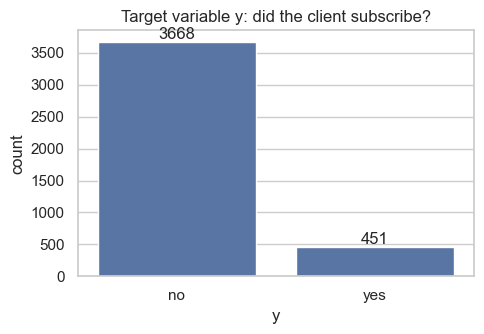

In [10]:
target_counts = df["y"].value_counts()
print(target_counts)
print((df["y"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x="y", order=["no", "yes"], ax=ax)
ax.set_title("Target variable y: did the client subscribe?")
for container in ax.containers:
    ax.bar_label(container)
plt.tight_layout()
plt.show()

**Target variable:** `y` ("has the client subscribed to a term deposit?").

**Is the dataset suited to classification, regression or both?**
- The target `y` is **binary (yes/no)**, so the dataset is naturally a **classification** dataset. The data is also **imbalanced**: only about **11%** of clients said yes. This matters for evaluation (Section 10).
- The dataset has **no natural numeric target**. `y` must **not** be treated as a number for regression. To demonstrate regression trees honestly, Section 11 uses a genuine numeric column of the dataset (`age`) as a clearly stated secondary target and explains why other numeric columns were rejected.

## 6. Data Preprocessing

### 6.1 Decisions and the reasons for them

| Issue | Decision | Why |
|---|---|---|
| Categorical text columns (`job`, `month`, ...) | **One-hot encoding** (`OneHotEncoder`) | scikit-learn trees need numeric input. One-hot creates one 0/1 column per category (e.g. `job_retired`), so the tree can ask "is the job retired?". Converting categories to integers (admin=0, blue-collar=1, ...) would invent a fake order. |
| `"unknown"` values | kept as a category | allowed by the documentation; avoids deleting ~20% of rows |
| Missing numeric values | none present | nothing to impute (verified in 5.5) |
| Feature scaling | **not done** | a tree only asks threshold questions such as `age <= 60.5`. Scaling (e.g. dividing age by 100) moves the threshold but produces exactly the same partition of the rows, so it cannot change the tree. |
| `pdays = 999` | kept | a threshold split handles the code naturally |
| `duration` | **excluded from the main model** | target leakage — see 6.2 |
| Data leakage in preprocessing | encoder **fitted on the training set only**, then applied to the test set | the test set must behave like unseen future data |

### 6.2 The `duration` leakage problem

The official data dictionary says about `duration`: *this attribute highly affects the output target (e.g., if duration=0 then y="no"). Yet, the duration is not known before a call is performed. Also, after the end of the call y is obviously known. Thus, this input should only be included for benchmark purposes and should be discarded if the intention is to have a realistic predictive model.*

A bank wants to decide **whom to call before calling**. At that moment the call duration does not exist yet. A model that uses `duration` gets information from the future, which inflates its apparent performance. Therefore:
- **Model B (main model, realistic): all inputs except `duration`** — used in Sections 7–10 and 15.
- **Model A (benchmark only): all inputs including `duration`** — compared with Model B in Section 10.4 to show the effect of the leak.

### 6.3 Encode the target

In [11]:
TARGET_MAP = {"no": 0, "yes": 1}        # readable mapping kept for the whole notebook
CLASS_NAMES = ["no", "yes"]              # index 0 -> "no", index 1 -> "yes"

y_class = df["y"].map(TARGET_MAP)
print("Target mapping:", TARGET_MAP)
print(pd.crosstab(df["y"], y_class, rownames=["original y"], colnames=["encoded"]))

Target mapping: {'no': 0, 'yes': 1}
encoded        0    1
original y           
no          3668    0
yes            0  451


### 6.4 Train / test split (80% / 20%, stratified)

`stratify=y_class` keeps the same ~11% share of "yes" in both parts; without it, a random split of an imbalanced dataset could put noticeably more or fewer positives in the test set.

In [12]:
LEAKY_COLUMN = "duration"
features_A = [c for c in df.columns if c != "y"]                        # benchmark (with duration)
features_B = [c for c in features_A if c != LEAKY_COLUMN]              # realistic (main)
numeric_B = [c for c in numeric_cols if c != LEAKY_COLUMN]

X_all = df.drop(columns="y")
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_all, y_class, test_size=0.2, random_state=RANDOM_STATE, stratify=y_class)

print("Training rows:", len(X_train_raw), "| Test rows:", len(X_test_raw))
print("Share of 'yes' in train: {:.2%} | in test: {:.2%}".format(y_train.mean(), y_test.mean()))
print("\nModel B features ({}): {}".format(len(features_B), features_B))

Training rows: 3295 | Test rows: 824
Share of 'yes' in train: 10.96% | in test: 10.92%

Model B features (19): ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


### 6.5 One-hot encoding (fit on training data only)

The small helper below builds the encoder: categorical columns are one-hot encoded, numeric columns pass through unchanged (no scaling). `handle_unknown="ignore"` means a category that appears only in the test set would simply get all-zero indicator columns instead of crashing.

In [13]:
def make_encoder(categorical_columns):
    # One-hot encode the listed categorical columns; pass all other columns through unchanged.
    encoder = ColumnTransformer(
        [("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_columns)],
        remainder="passthrough",
        verbose_feature_names_out=False,
    )
    return encoder.set_output(transform="pandas")   # keep readable column names such as "job_retired"


encoder_B = make_encoder(categorical_cols)
X_train = encoder_B.fit_transform(X_train_raw[features_B])   # learn the category list from TRAIN only
X_test = encoder_B.transform(X_test_raw[features_B])         # apply the same encoding to TEST

print("Encoded training matrix:", X_train.shape, "| Encoded test matrix:", X_test.shape)
print("First 12 encoded column names:", list(X_train.columns[:12]))
X_train.head(3)

Encoded training matrix: (3295, 62) | Encoded test matrix: (824, 62)
First 12 encoded column names: ['job_admin.', 'job_blue-collar', 'job_entrepreneur', 'job_housemaid', 'job_management', 'job_retired', 'job_self-employed', 'job_services', 'job_student', 'job_technician', 'job_unemployed', 'job_unknown']


,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,job_unknown,marital_divorced,marital_married,marital_single,...,day_of_week_thu,day_of_week_tue,day_of_week_wed,poutcome_failure,poutcome_nonexistent,poutcome_success,age,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
2782,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,48,3,999,0,-1.8,92.893,-46.2,1.291,5099.1
2547,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,1.0,0.0,0.0,34,2,999,1,-1.8,92.893,-46.2,1.344,5099.1
2994,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,0.0,0.0,1.0,0.0,1.0,0.0,47,1,999,0,-1.8,92.893,-46.2,1.334,5099.1


The 19 raw inputs of Model B became **62 numeric columns** (53 one-hot indicator columns + 9 untouched numeric columns). This `X_train` / `X_test` pair is used for all classification models below.

## 7. Classification Decision Tree — *Evidence for Outcome 1*

### 7.1 Vocabulary

| Term | Meaning (in this dataset) |
|---|---|
| **Root node** | The first node; it contains **all** training rows (3,295 clients) and asks the single most useful question. |
| **Split** | A yes/no test on one feature, e.g. `nr.employed <= 5087.65`. Rows that satisfy it go left, the rest go right. |
| **Branch** | The edge from a node to one of its children — one answer to the split question. |
| **Internal node** | Any non-leaf node below the root: it holds a subset of rows and asks another question. |
| **Leaf (terminal node)** | A node that is not split further. It stores the class proportions of its training rows and predicts the majority class. |
| **Impurity** | How mixed the classes are inside a node. A node containing only "no" clients is **pure** (impurity 0). Measured by Gini or entropy (Section 8). |
| **Stopping condition** | The rule that decides when a node becomes a leaf: the node is pure, it has too few samples (`min_samples_split`), the maximum depth is reached (`max_depth`), a child would be too small (`min_samples_leaf`), or no split reduces impurity. |

### 7.2 How the tree is induced (the algorithm)

scikit-learn uses an optimised version of **CART** (Classification And Regression Trees). It is a **greedy, top-down, recursive** algorithm:

1. Start at the root with all training rows.
2. For **every feature** and **every possible threshold** (midpoints between sorted distinct values), compute how much the split would **reduce impurity**.
3. Choose the feature/threshold with the **largest impurity decrease**, and split the rows into a left and a right child.
4. Repeat steps 2–3 separately inside each child.
5. Stop when a stopping condition holds; the node becomes a leaf that predicts its majority class.

"Greedy" means each split is the best one *at that moment* — the algorithm never goes back to change an earlier split. CART always makes **binary** splits.

### 7.3 Train the baseline classification tree

The baseline uses scikit-learn's **default settings**: `criterion="gini"`, no depth limit, `min_samples_split=2`, `min_samples_leaf=1` — i.e. the tree grows until its leaves are pure (or cannot be split).

In [14]:
tree_clf = DecisionTreeClassifier(random_state=RANDOM_STATE)   # all other settings are defaults
tree_clf.fit(X_train, y_train)

print("Splitting criterion actually used:", tree_clf.criterion)
print("Training accuracy:", round(accuracy_score(y_train, tree_clf.predict(X_train)), 4))
print("Test accuracy:    ", round(accuracy_score(y_test, tree_clf.predict(X_test)), 4))
print("Tree depth:       ", tree_clf.get_depth())
print("Number of leaves: ", tree_clf.get_n_leaves())
print("Total nodes:      ", tree_clf.tree_.node_count)

Splitting criterion actually used: gini
Training accuracy: 1.0
Test accuracy:     0.8265
Tree depth:        25
Number of leaves:  436
Total nodes:       871


The fully grown tree fits the training data perfectly (training accuracy = 1.0) but is much less accurate on the test data, and it is very large. This gap is a first sign of **overfitting**; it is examined and fixed by pruning in Section 15.

### 7.4 Anatomy of the fitted tree (root node)

In [15]:
tree_structure = tree_clf.tree_
feature_names = list(X_train.columns)

root_feature = feature_names[tree_structure.feature[0]]
root_threshold = tree_structure.threshold[0]
root_samples = tree_structure.n_node_samples[0]
root_counts = np.bincount(y_train, minlength=2)

print(f"Root node : '{root_feature} <= {root_threshold:.3f}'")
print(f"            samples = {root_samples}, class counts [no, yes] = {root_counts.tolist()}, "
      f"gini = {tree_structure.impurity[0]:.4f}")
left, right = tree_structure.children_left[0], tree_structure.children_right[0]
for side, node in [("Left child (condition TRUE) ", left), ("Right child (condition FALSE)", right)]:
    print(f"{side}: samples = {tree_structure.n_node_samples[node]}, gini = {tree_structure.impurity[node]:.4f}")

is_leaf = tree_structure.children_left == -1
print(f"\nInternal nodes (incl. root): {(~is_leaf).sum()} | Leaves: {is_leaf.sum()}")

Root node : 'nr.employed <= 5087.650'
            samples = 3295, class counts [no, yes] = [2934, 361], gini = 0.1951
Left child (condition TRUE) : samples = 432, gini = 0.4916
Right child (condition FALSE): samples = 2863, gini = 0.1135

Internal nodes (incl. root): 435 | Leaves: 436


### 7.5 Tree visualisation

The full tree has hundreds of nodes and cannot be read on one page. **For visualisation only**, `plot_tree(max_depth=3)` draws just the top three levels of the *same* fitted model (the model itself is not changed). Each box shows the split, the Gini impurity, the number of samples, the class counts (`value`) and the majority class. Orange = mostly "no", blue = mostly "yes".

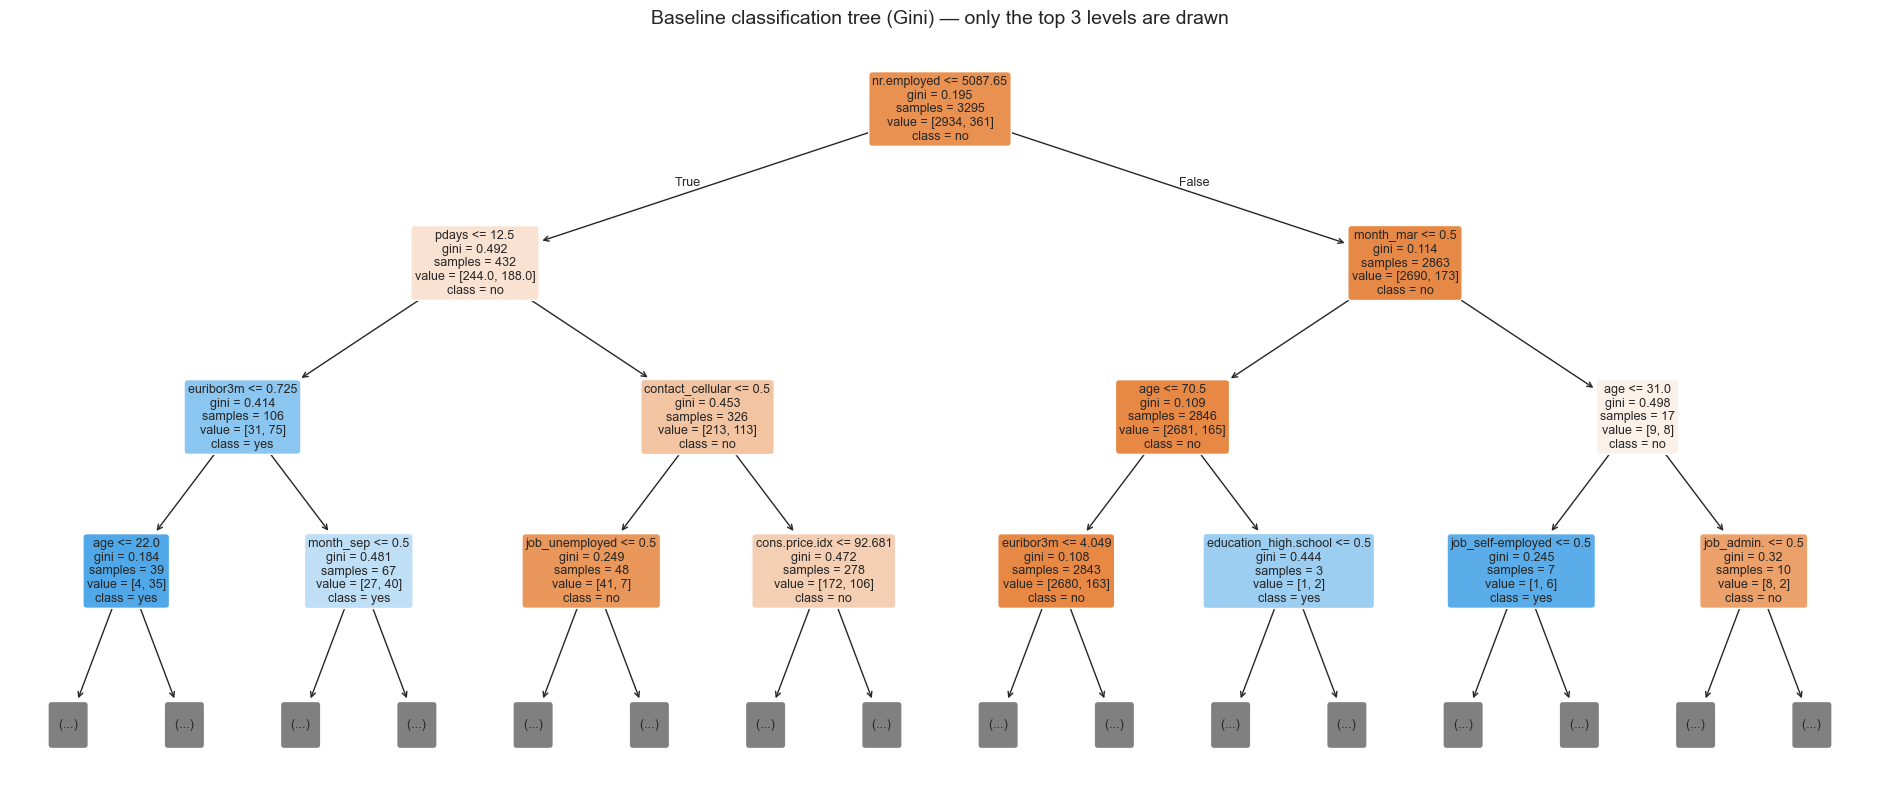

In [16]:
fig, ax = plt.subplots(figsize=(24, 10))
plot_tree(tree_clf, max_depth=3, feature_names=feature_names, class_names=CLASS_NAMES,
          filled=True, rounded=True, impurity=True, fontsize=9, ax=ax)
ax.set_title("Baseline classification tree (Gini) — only the top 3 levels are drawn", fontsize=14)
plt.show()

The same top of the tree written as **IF–THEN rules** (useful for explaining the model in words):

In [17]:
print(export_text(tree_clf, feature_names=feature_names, max_depth=2, show_weights=True))

|--- nr.employed <= 5087.65
|   |--- pdays <= 12.50
|   |   |--- euribor3m <= 0.72
|   |   |   |--- truncated branch of depth 5
|   |   |--- euribor3m >  0.72
|   |   |   |--- truncated branch of depth 11
|   |--- pdays >  12.50
|   |   |--- contact_cellular <= 0.50
|   |   |   |--- truncated branch of depth 7
|   |   |--- contact_cellular >  0.50
|   |   |   |--- truncated branch of depth 23
|--- nr.employed >  5087.65
|   |--- month_mar <= 0.50
|   |   |--- age <= 70.50
|   |   |   |--- truncated branch of depth 21
|   |   |--- age >  70.50
|   |   |   |--- truncated branch of depth 2
|   |--- month_mar >  0.50
|   |   |--- age <= 31.00
|   |   |   |--- truncated branch of depth 2
|   |   |--- age >  31.00
|   |   |   |--- truncated branch of depth 4



### 7.6 Which features does the tree use most?

**Feature importance** = the total impurity decrease contributed by a feature over all its splits, normalised to sum to 1.

nr.employed                    0.1698
age                            0.1666
euribor3m                      0.0972
campaign                       0.0619
pdays                          0.0416
cons.price.idx                 0.0298
job_admin.                     0.0252
education_high.school          0.0200
education_university.degree    0.0187
marital_divorced               0.0175
dtype: float64


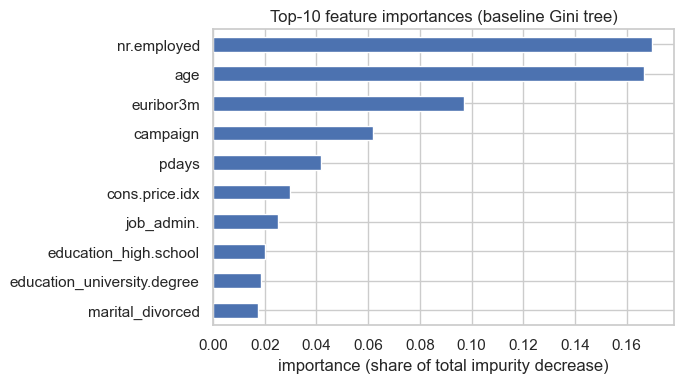

In [18]:
importances = pd.Series(tree_clf.feature_importances_, index=feature_names).sort_values(ascending=False)
print(importances.head(10).round(4))

fig, ax = plt.subplots(figsize=(7, 4))
importances.head(10).iloc[::-1].plot.barh(ax=ax)
ax.set_title("Top-10 feature importances (baseline Gini tree)")
ax.set_xlabel("importance (share of total impurity decrease)")
plt.tight_layout()
plt.show()

## 8. Attribute Selection Measures for Classification — *Evidence for Outcome 2*

An **attribute selection measure** scores every candidate split so the algorithm can pick the best one. All common measures are built on a node **impurity** function. Let $p_k$ be the proportion of class $k$ in a node $D$ (here $k \in \{\text{no}, \text{yes}\}$).

**1. Entropy** (from information theory; measured in bits)
$$H(D) = -\sum_{k} p_k \log_2 p_k$$
0 for a pure node, 1 bit for a 50/50 node (two classes).

**2. Information Gain** (used by ID3 / C4.5) — the reduction in entropy after splitting $D$ into children $D_1, \dots, D_m$:
$$IG(D, A) = H(D) - \sum_{j=1}^{m} \frac{|D_j|}{|D|}\, H(D_j)$$
(C4.5 additionally divides by the "split information" to get the **Gain Ratio**, which penalises attributes with many values. CART makes only binary splits, so it does not need this correction.)

**3. Gini Impurity** (used by CART — **scikit-learn's default**)
$$G(D) = 1 - \sum_{k} p_k^2$$
0 for a pure node, 0.5 for a 50/50 two-class node. It is the probability of misclassifying a random row if it were labelled randomly according to the node's class proportions. The quality of a split is the **Gini decrease**:
$$\Delta G = G(D) - \sum_{j} \frac{|D_j|}{|D|}\, G(D_j)$$

**How the best split is selected:** compute the chosen decrease ($\Delta G$ or $IG$) for every feature and every threshold, and take the maximum. Weighting each child by its size ($|D_j|/|D|$) prevents a tiny pure child from looking artificially good.

> **Important:** `DecisionTreeClassifier()` uses **`criterion="gini"`** by default — **not** information gain. Information gain is obtained with `criterion="entropy"` (or `"log_loss"`, which in scikit-learn is the same measure). The baseline tree in Section 7 therefore used **Gini decrease**.

### 8.1 Impurity functions written from scratch

In [19]:
def gini_impurity(labels):
    proportions = np.bincount(labels, minlength=2) / len(labels)
    return 1.0 - np.sum(proportions ** 2)


def entropy(labels):
    proportions = np.bincount(labels, minlength=2) / len(labels)
    proportions = proportions[proportions > 0]          # 0 * log(0) is defined as 0
    return -np.sum(proportions * np.log2(proportions))


def evaluate_split(labels, goes_left):
    # Score one binary split with both measures. goes_left is a boolean mask over the rows.
    left, right = labels[goes_left], labels[~goes_left]
    w_left, w_right = len(left) / len(labels), len(right) / len(labels)
    gini_after = w_left * gini_impurity(left) + w_right * gini_impurity(right)
    entropy_after = w_left * entropy(left) + w_right * entropy(right)
    return {
        "n_left": len(left), "n_right": len(right),
        "gini_decrease": gini_impurity(labels) - gini_after,
        "information_gain": entropy(labels) - entropy_after,
    }


y_train_arr = y_train.to_numpy()
n_no, n_yes = np.bincount(y_train_arr)
n = len(y_train_arr)
p_no, p_yes = n_no / n, n_yes / n

print(f"Root node of the training set: {n} rows -> {n_no} 'no', {n_yes} 'yes'")
print(f"p(no) = {p_no:.4f}, p(yes) = {p_yes:.4f}\n")
print(f"Gini    = 1 - ({p_no:.4f}^2 + {p_yes:.4f}^2) = {1 - p_no**2 - p_yes**2:.4f}")
print(f"Entropy = -({p_no:.4f}*log2({p_no:.4f}) + {p_yes:.4f}*log2({p_yes:.4f})) = "
      f"{-(p_no*np.log2(p_no) + p_yes*np.log2(p_yes)):.4f} bits")
print(f"\nCheck with the functions: gini = {gini_impurity(y_train_arr):.4f}, entropy = {entropy(y_train_arr):.4f}")
print(f"sklearn's root-node gini   = {tree_clf.tree_.impurity[0]:.4f}")

Root node of the training set: 3295 rows -> 2934 'no', 361 'yes'
p(no) = 0.8904, p(yes) = 0.1096

Gini    = 1 - (0.8904^2 + 0.1096^2) = 0.1951
Entropy = -(0.8904*log2(0.8904) + 0.1096*log2(0.1096)) = 0.4986 bits

Check with the functions: gini = 0.1951, entropy = 0.4986
sklearn's root-node gini   = 0.1951


### 8.2 A worked split on the real data: "was the previous campaign a success?"

`poutcome_success` is a one-hot column (1 = the previous campaign succeeded for this client). The split is `poutcome_success <= 0.5`.

In [20]:
goes_left = (X_train["poutcome_success"] <= 0.5).to_numpy()
left_labels, right_labels = y_train_arr[goes_left], y_train_arr[~goes_left]

for name, part in [("Left  (previous outcome NOT success)", left_labels), ("Right (previous outcome = success)  ", right_labels)]:
    counts = np.bincount(part, minlength=2)
    print(f"{name}: {len(part):4d} rows, [no, yes] = {counts.tolist()}, "
          f"yes-rate = {counts[1] / len(part):.3f}, gini = {gini_impurity(part):.4f}, entropy = {entropy(part):.4f}")

result = evaluate_split(y_train_arr, goes_left)
print(f"\nGini decrease    = {result['gini_decrease']:.5f}")
print(f"Information gain = {result['information_gain']:.5f} bits")

Left  (previous outcome NOT success): 3175 rows, [no, yes] = [2889, 286], yes-rate = 0.090, gini = 0.1639, entropy = 0.4367
Right (previous outcome = success)  :  120 rows, [no, yes] = [45, 75], yes-rate = 0.625, gini = 0.4688, entropy = 0.9544

Gini decrease    = 0.02008
Information gain = 0.04300 bits


Clients whose previous campaign was a success subscribe far more often than others, so the right child is much "bluer". But it holds only a small group of rows, so the **weighted** improvement is moderate. To find the *best* root split we must check every feature.

### 8.3 Searching all features and thresholds (what the algorithm does at the root)

In [21]:
def best_split_for_feature(values, labels):
    # Try every midpoint threshold of one feature; return the best threshold for each measure.
    distinct = np.unique(values)
    best = {"gini_threshold": None, "gini_decrease": 0.0, "ig_threshold": None, "information_gain": 0.0}
    for threshold in (distinct[:-1] + distinct[1:]) / 2:
        scores = evaluate_split(labels, values <= threshold)
        if scores["gini_decrease"] > best["gini_decrease"]:
            best["gini_threshold"], best["gini_decrease"] = threshold, scores["gini_decrease"]
        if scores["information_gain"] > best["information_gain"]:
            best["ig_threshold"], best["information_gain"] = threshold, scores["information_gain"]
    return best


root_search = pd.DataFrame({col: best_split_for_feature(X_train[col].to_numpy(), y_train_arr)
                            for col in X_train.columns}).T
root_search = root_search.astype({"gini_decrease": float, "information_gain": float})

print("Top 8 candidate root splits ranked by GINI decrease:")
display(root_search.sort_values("gini_decrease", ascending=False).head(8).round(5))
print("Top 8 candidate root splits ranked by INFORMATION GAIN:")
display(root_search.sort_values("information_gain", ascending=False).head(8).round(5))

Top 8 candidate root splits ranked by GINI decrease:


,gini_threshold,gini_decrease,ig_threshold,information_gain
nr.employed,5087.6500,0.03200,5087.6500,0.08309
euribor3m,1.0855,0.02793,1.2755,0.07194
pdays,12.5000,0.02153,12.5000,0.04602
poutcome_success,0.5000,0.02008,0.5000,0.04300
emp.var.rate,-0.6500,0.01545,-0.6500,0.05318
cons.conf.idx,-35.4500,0.01169,-35.4500,0.02929
previous,1.5000,0.01166,1.5000,0.02611
poutcome_nonexistent,0.5000,0.00856,0.5000,0.02546


Top 8 candidate root splits ranked by INFORMATION GAIN:


,gini_threshold,gini_decrease,ig_threshold,information_gain
nr.employed,5087.6500,0.03200,5087.6500,0.08309
euribor3m,1.0855,0.02793,1.2755,0.07194
emp.var.rate,-0.6500,0.01545,-0.6500,0.05318
pdays,12.5000,0.02153,12.5000,0.04602
poutcome_success,0.5000,0.02008,0.5000,0.04300
cons.conf.idx,-35.4500,0.01169,-35.4500,0.02929
previous,1.5000,0.01166,1.5000,0.02611
poutcome_nonexistent,0.5000,0.00856,0.5000,0.02546


In [22]:
tree_entropy = DecisionTreeClassifier(criterion="entropy", random_state=RANDOM_STATE).fit(X_train, y_train)

best_gini_feature = root_search["gini_decrease"].idxmax()
best_ig_feature = root_search["information_gain"].idxmax()

print("My search, Gini:            ", best_gini_feature, "<=", round(root_search.loc[best_gini_feature, "gini_threshold"], 3))
print("sklearn root, criterion=gini:", feature_names[tree_clf.tree_.feature[0]], "<=", round(tree_clf.tree_.threshold[0], 3))
print()
print("My search, Information Gain:    ", best_ig_feature, "<=", round(root_search.loc[best_ig_feature, "ig_threshold"], 3))
print("sklearn root, criterion=entropy:", feature_names[tree_entropy.tree_.feature[0]], "<=", round(tree_entropy.tree_.threshold[0], 3))

My search, Gini:             nr.employed <= 5087.65
sklearn root, criterion=gini: nr.employed <= 5087.65

My search, Information Gain:     nr.employed <= 5087.65
sklearn root, criterion=entropy: nr.employed <= 5087.65


The hand-written search picks **the same root split as scikit-learn** for both criteria — this confirms that the library does exactly what the formulas describe: score every candidate split, then choose the maximum.

Notice that several **economic indicators** (`nr.employed`, `euribor3m`, `emp.var.rate`, `cons.price.idx`) are near the top. They are strongly correlated with each other (they all describe the economic climate at the time of the call) and so give similar splits.

### 8.4 Comparing `criterion="gini"`, `"entropy"` and `"log_loss"`

Each criterion is compared twice: fully grown (default) and limited to `max_depth=5`. All other settings are identical.

In [23]:
def classification_summary(model, X_tr, y_tr, X_te, y_te):
    # One-row summary of a fitted classifier (positive class = "yes" = 1).
    pred = model.predict(X_te)
    return {
        "Depth": model.get_depth(), "Leaves": model.get_n_leaves(),
        "Train Acc": accuracy_score(y_tr, model.predict(X_tr)),
        "Test Acc": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred, zero_division=0),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
    }


criterion_rows = []
for criterion in ["gini", "entropy", "log_loss"]:
    for max_depth in [None, 5]:
        model = DecisionTreeClassifier(criterion=criterion, max_depth=max_depth, random_state=RANDOM_STATE)
        model.fit(X_train, y_train)
        row = {"Criterion": criterion, "max_depth": "None" if max_depth is None else max_depth,
               "Root split": f"{feature_names[model.tree_.feature[0]]} <= {model.tree_.threshold[0]:.2f}"}
        row.update(classification_summary(model, X_train, y_train, X_test, y_test))
        criterion_rows.append(row)

criterion_comparison = pd.DataFrame(criterion_rows)
criterion_comparison.round(4)

,Criterion,max_depth,Root split,Depth,Leaves,Train Acc,Test Acc,Precision,Recall,F1
0,gini,None,nr.employed <= 5087.65,25,436,1.0000,0.8265,0.2022,0.2000,0.2011
1,gini,5,nr.employed <= 5087.65,5,25,0.9102,0.8920,0.5385,0.0778,0.1359
2,entropy,None,nr.employed <= 5087.65,29,427,1.0000,0.8398,0.2812,0.3000,0.2903
3,entropy,5,nr.employed <= 5087.65,5,27,0.9105,0.8956,0.6667,0.0889,0.1569
4,log_loss,None,nr.employed <= 5087.65,29,427,1.0000,0.8398,0.2812,0.3000,0.2903
5,log_loss,5,nr.employed <= 5087.65,5,27,0.9105,0.8956,0.6667,0.0889,0.1569


**Observations**
- Gini and entropy usually choose similar splits, because both curves are low for pure nodes and high for mixed nodes. Differences appear deeper in the tree, where one criterion can rank two near-equal splits differently; this gives trees with a different number of leaves and slightly different test scores.
- `log_loss` produces **exactly the same tree as `entropy`** — in scikit-learn they are two names for the same (Shannon entropy / information gain) criterion.
- Gini is the default mainly because it is **cheaper to compute** (no logarithm) and in practice gives very similar trees.
- With either criterion, limiting depth changes the results much more than switching criteria — the stopping rules matter more than the impurity measure (see Section 15).

## 9. Prediction on Unseen Data — *Evidence for Outcome 3*

The baseline tree (Section 7) never saw the test rows. `predict()` sends each row down the tree — at every node it follows the branch matching the row's value — and returns the majority class of the leaf it reaches. `predict_proba()` returns that leaf's class proportions.

To show both outcomes, the examples below are the **first five test clients** plus the **first three test clients who actually subscribed**.

In [24]:
y_pred = tree_clf.predict(X_test)
y_proba_yes = tree_clf.predict_proba(X_test)[:, 1]      # column 1 = probability of "yes"

y_test_arr = y_test.to_numpy()
sample_positions = list(range(5)) + [p for p in np.where(y_test_arr == 1)[0] if p >= 5][:3]

for number, pos in enumerate(sample_positions, start=1):
    print(f"Sample {number} (row {X_test.index[pos]} of the CSV):  Actual = {CLASS_NAMES[y_test_arr[pos]]:3s} | "
          f"Predicted = {CLASS_NAMES[y_pred[pos]]:3s} | P(yes) = {y_proba_yes[pos]:.2f} | "
          f"{'correct' if y_pred[pos] == y_test_arr[pos] else 'WRONG'}")

Sample 1 (row 2925 of the CSV):  Actual = no  | Predicted = no  | P(yes) = 0.00 | correct
Sample 2 (row 3573 of the CSV):  Actual = no  | Predicted = no  | P(yes) = 0.00 | correct
Sample 3 (row 1186 of the CSV):  Actual = no  | Predicted = no  | P(yes) = 0.00 | correct
Sample 4 (row 702 of the CSV):  Actual = no  | Predicted = no  | P(yes) = 0.00 | correct
Sample 5 (row 225 of the CSV):  Actual = no  | Predicted = no  | P(yes) = 0.00 | correct
Sample 6 (row 3453 of the CSV):  Actual = yes | Predicted = no  | P(yes) = 0.00 | WRONG
Sample 7 (row 1119 of the CSV):  Actual = yes | Predicted = yes | P(yes) = 1.00 | correct
Sample 8 (row 674 of the CSV):  Actual = yes | Predicted = yes | P(yes) = 1.00 | correct


In [25]:
examples = X_test_raw.iloc[sample_positions][["age", "job", "contact", "month", "poutcome", "euribor3m", "nr.employed"]].copy()
examples["actual_y"] = [CLASS_NAMES[v] for v in y_test_arr[sample_positions]]
examples["predicted_y"] = [CLASS_NAMES[v] for v in y_pred[sample_positions]]
examples["P(yes)"] = y_proba_yes[sample_positions].round(2)
examples

,age,job,contact,month,poutcome,euribor3m,nr.employed,actual_y,predicted_y,P(yes)
2925,41,blue-collar,cellular,apr,failure,1.405,5099.1,no,no,0.0
3573,24,blue-collar,cellular,may,nonexistent,1.244,5099.1,no,no,0.0
1186,31,self-employed,cellular,aug,nonexistent,4.966,5228.1,no,no,0.0
702,33,admin.,telephone,may,nonexistent,4.860,5191.0,no,no,0.0
225,38,technician,cellular,may,failure,1.244,5099.1,no,no,0.0
3453,37,management,cellular,dec,nonexistent,0.715,5023.5,yes,no,0.0
1119,35,admin.,cellular,jun,nonexistent,1.260,5076.2,yes,yes,1.0
674,58,unemployed,cellular,nov,nonexistent,1.041,4963.6,yes,yes,1.0


**What a prediction means here:** "Predicted = yes" means that clients with a similar profile and economic situation (the same leaf) mostly subscribed in the training data, so the bank should prioritise calling this client. "Predicted = no" means that similar clients mostly did not subscribe.

**Why are the probabilities only 0.00 or 1.00?** The fully grown tree keeps splitting until each leaf is (almost) pure, so almost every leaf contains only one class. Its `predict_proba` is therefore over-confident:

In [26]:
print("Distinct P(yes) values produced by the unpruned tree on the test set:")
print(pd.Series(y_proba_yes).round(2).value_counts().sort_index())

Distinct P(yes) values produced by the unpruned tree on the test set:
0.0    735
1.0     89
Name: count, dtype: int64


A pruned tree has larger, mixed leaves and gives more useful graded probabilities — shown in Section 15.

### 9.1 Following one prediction through the tree

`decision_path()` lists every node a row visits, so a prediction can be explained as a chain of rules:

In [27]:
def explain_prediction(model, X_rows, position):
    row = X_rows.iloc[[position]]
    visited_nodes = model.decision_path(row).indices
    t = model.tree_
    for node in visited_nodes:
        if t.children_left[node] == -1:           # leaf
            counts = t.value[node][0] * t.n_node_samples[node]
            print(f"  -> LEAF {node}: training rows [no, yes] = {counts.round().astype(int).tolist()} "
                  f"=> predict '{CLASS_NAMES[int(np.argmax(counts))]}'")
        else:
            name, threshold = X_rows.columns[t.feature[node]], t.threshold[node]
            value = row.iloc[0, t.feature[node]]
            direction = "<=" if value <= threshold else "> "
            print(f"  node {node:4d}: {name} = {value} {direction} {threshold:.3f}")


first_yes = sample_positions[5]
print(f"Decision path of Sample 6 (actual = {CLASS_NAMES[y_test_arr[first_yes]]}):")
explain_prediction(tree_clf, X_test, first_yes)

Decision path of Sample 6 (actual = yes):
  node    0: nr.employed = 5023.5 <= 5087.650
  node    1: pdays = 999 >  12.500
  node   55: contact_cellular = 1.0 >  0.500
  node   73: cons.price.idx = 92.713 >  92.681
  node  135: age = 37 >  23.500
  node  137: age = 37 <= 80.500
  node  138: job_management = 1.0 >  0.500
  node  234: euribor3m = 0.715 >  0.687
  -> LEAF 236: training rows [no, yes] = [8, 0] => predict 'no'


## 10. Classification Evaluation — *Evidence for Outcome 4*

Metrics for the baseline tree on the **test set** (positive class = "yes"):

| Metric | Formula | Question it answers |
|---|---|---|
| Accuracy | (TP + TN) / all | What fraction of all predictions is correct? |
| Precision | TP / (TP + FP) | Of the clients predicted "yes", how many really subscribed? |
| Recall | TP / (TP + FN) | Of the clients who really subscribed, how many did the model find? |
| F1-score | 2·P·R / (P + R) | Harmonic mean of precision and recall |

### 10.1 Accuracy, precision, recall, F1

In [28]:
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred)
test_recall = recall_score(y_test, y_pred)
test_f1 = f1_score(y_test, y_pred)

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Precision: {test_precision:.4f}")
print(f"Recall   : {test_recall:.4f}")
print(f"F1-score : {test_f1:.4f}")

Accuracy : 0.8265
Precision: 0.2022
Recall   : 0.2000
F1-score : 0.2011


### 10.2 Confusion matrix and classification report

TN = 663 (correct 'no') | FP = 71 (predicted yes, actually no)
FN = 72 (missed subscribers) | TP = 18 (correct 'yes')



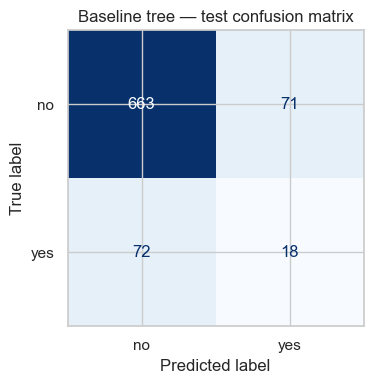

              precision    recall  f1-score   support

          no     0.9020    0.9033    0.9027       734
         yes     0.2022    0.2000    0.2011        90

    accuracy                         0.8265       824
   macro avg     0.5521    0.5516    0.5519       824
weighted avg     0.8256    0.8265    0.8260       824



In [29]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
print(f"TN = {tn} (correct 'no') | FP = {fp} (predicted yes, actually no)")
print(f"FN = {fn} (missed subscribers) | TP = {tp} (correct 'yes')\n")

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Baseline tree — test confusion matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4))

### 10.3 Why accuracy alone is misleading here

Only about 11% of clients say "yes". A "model" that ignores the input and always answers "no" already scores high accuracy while being useless to the bank:

In [30]:
majority_model = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
majority_pred = majority_model.predict(X_test)
print(f"Always-'no' baseline -> accuracy = {accuracy_score(y_test, majority_pred):.4f}, "
      f"recall = {recall_score(y_test, majority_pred):.4f}, F1 = {f1_score(y_test, majority_pred):.4f}")
print(f"Baseline tree        -> accuracy = {test_accuracy:.4f}, recall = {test_recall:.4f}, F1 = {test_f1:.4f}")

Always-'no' baseline -> accuracy = 0.8908, recall = 0.0000, F1 = 0.0000
Baseline tree        -> accuracy = 0.8265, recall = 0.2000, F1 = 0.2011


The always-"no" model has **higher accuracy than the unpruned tree but finds zero subscribers** (recall = 0). With an imbalanced target, accuracy is dominated by the majority class, so **precision, recall and F1 for the minority "yes" class** (and the confusion matrix) are the numbers that show whether the model is actually useful. The unpruned tree's low precision *and* low accuracy are also symptoms of overfitting — Section 15 improves this.

### 10.4 Data-leakage check: Model A (with `duration`) vs Model B (without)

Both models use exactly the same rows, split and settings; the only difference is the `duration` column.

In [31]:
encoder_A = make_encoder(categorical_cols)
X_train_A = encoder_A.fit_transform(X_train_raw[features_A])
X_test_A = encoder_A.transform(X_test_raw[features_A])

leakage_rows = []
for max_depth in [None, 5]:
    for label, X_tr, X_te in [("Model A: with duration", X_train_A, X_test_A),
                              ("Model B: without duration", X_train, X_test)]:
        model = DecisionTreeClassifier(max_depth=max_depth, random_state=RANDOM_STATE).fit(X_tr, y_train)
        row = {"Model": label, "max_depth": "None" if max_depth is None else max_depth}
        row.update(classification_summary(model, X_tr, y_train, X_te, y_test))
        leakage_rows.append(row)
        if label.startswith("Model A") and max_depth == 5:
            model_A_depth5 = model

leakage_comparison = pd.DataFrame(leakage_rows)
display(leakage_comparison.round(4))

imp_A = pd.Series(model_A_depth5.feature_importances_, index=X_train_A.columns).sort_values(ascending=False)
print("Model A (max_depth=5) — top 5 feature importances:")
print(imp_A.head(5).round(4))

,Model,max_depth,Depth,Leaves,Train Acc,Test Acc,Precision,Recall,F1
0,Model A: with duration,None,20,253,1.0000,0.8883,0.4884,0.4667,0.4773
1,Model B: without duration,None,25,436,1.0000,0.8265,0.2022,0.2000,0.2011
2,Model A: with duration,5,5,32,0.9305,0.9090,0.6190,0.4333,0.5098
3,Model B: without duration,5,5,25,0.9102,0.8920,0.5385,0.0778,0.1359


Model A (max_depth=5) — top 5 feature importances:
duration       0.4767
nr.employed    0.3242
pdays          0.0474
month_mar      0.0307
age            0.0300
dtype: float64


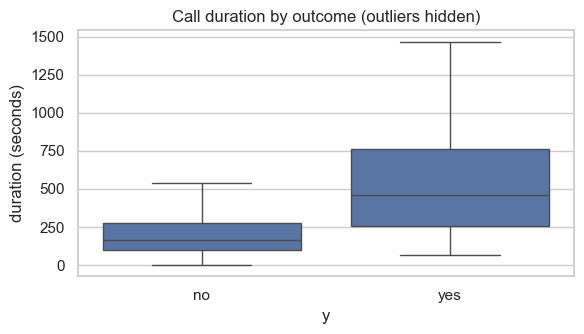

y
no     165.0
yes    458.0
Name: median duration (s), dtype: float64


In [32]:
fig, ax = plt.subplots(figsize=(6, 3.5))
sns.boxplot(data=df, x="y", y="duration", order=["no", "yes"], ax=ax, showfliers=False)
ax.set_title("Call duration by outcome (outliers hidden)")
ax.set_ylabel("duration (seconds)")
plt.tight_layout()
plt.show()
print(df.groupby("y")["duration"].median().rename("median duration (s)"))

**Interpretation:** With `duration`, the tree becomes clearly better — especially at finding subscribers — and `duration` becomes the dominant feature. But this improvement is **not usable**: a long call is partly a *consequence* of the client being interested (a client who wants to subscribe stays on the phone to complete it), and the duration is only known after the call, when `y` is already known. Model A answers "given how the call went, did it succeed?", while the bank needs "should we call this client?". **Model B is the honest, deployable model**, so it is the main model of this notebook; Model A is kept only as the benchmark the dataset authors suggest.

## 11. Regression Decision Tree — *Evidence for Outcome 5*

### 11.1 Choosing an honest regression target

The Bank Marketing dataset is a **classification** dataset: its target `y` is yes/no. Coding it as 0/1 and "regressing" on it would just be a disguised classifier, so `y` is **not** used for regression. Instead I examined the genuine numeric columns:

| Candidate target | Verdict | Reason |
|---|---|---|
| `y` (0/1) | rejected | categorical target; not a regression problem |
| `duration` | rejected | only known after the call (leakage column); and it is essentially unpredictable from pre-call information (checked below: R² ≈ 0) |
| `campaign`, `pdays`, `previous` | rejected | counts/codes driven by the bank's calling schedule; `pdays` is 96% the code 999 |
| `euribor3m`, `nr.employed`, ... | not the main task | national economic indicators determined by the date of the call, not by the client (they are used only for the 1-D piece-wise illustration in Section 14) |
| **`age`** | **chosen** | a real, continuous, client-level quantity with a meaningful unit (years) and a plausible relationship with the client profile |

**Regression task:** *predict a client's **age** (years) from their profile*: `job`, `marital`, `education`, `default`, `housing`, `loan`.
This is a genuine column of the dataset — **nothing is fabricated or derived**. A realistic use would be estimating the age of clients whose age is missing from a CRM record or for profiling. **Limitation:** this is a secondary task created to demonstrate regression trees; it is not the business goal of the original dataset, and a profile can only partly determine age (students are young and retired people are old, but most jobs span many ages), so a moderate R² is expected.

In [33]:
# Quick evidence for rejecting `duration` as a regression target:
# can a tree predict call duration from information available BEFORE the call?
check_encoder = make_encoder(categorical_cols)
Xd_train = check_encoder.fit_transform(X_train_raw[features_B])
Xd_test = check_encoder.transform(X_test_raw[features_B])
duration_tree = DecisionTreeRegressor(max_depth=4, random_state=RANDOM_STATE)
duration_tree.fit(Xd_train, X_train_raw["duration"])
print("Test R² when predicting duration from pre-call features:",
      round(r2_score(X_test_raw["duration"], duration_tree.predict(Xd_test)), 4))

Test R² when predicting duration from pre-call features: -0.0074


An R² at or below zero means the tree is no better than always predicting the average duration — confirming that `duration` is not a sensible regression target.

### 11.2 Regression data and split

In [34]:
REG_TARGET = "age"
reg_features = ["job", "marital", "education", "default", "housing", "loan"]

X_reg = df[reg_features]
y_reg = df[REG_TARGET]

Xr_train_raw, Xr_test_raw, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE)   # no stratify: the target is continuous

encoder_reg = make_encoder(reg_features)
Xr_train = encoder_reg.fit_transform(Xr_train_raw)            # fitted on the training part only
Xr_test = encoder_reg.transform(Xr_test_raw)

print("Train:", Xr_train.shape, "| Test:", Xr_test.shape)
print(f"Target '{REG_TARGET}' in train: mean = {yr_train.mean():.2f}, std = {yr_train.std():.2f}, "
      f"min = {yr_train.min()}, max = {yr_train.max()}")

Train:

 (3295, 32) | Test: (824, 32)
Target 'age' in train: mean = 40.07, std = 10.32, min = 18, max = 88


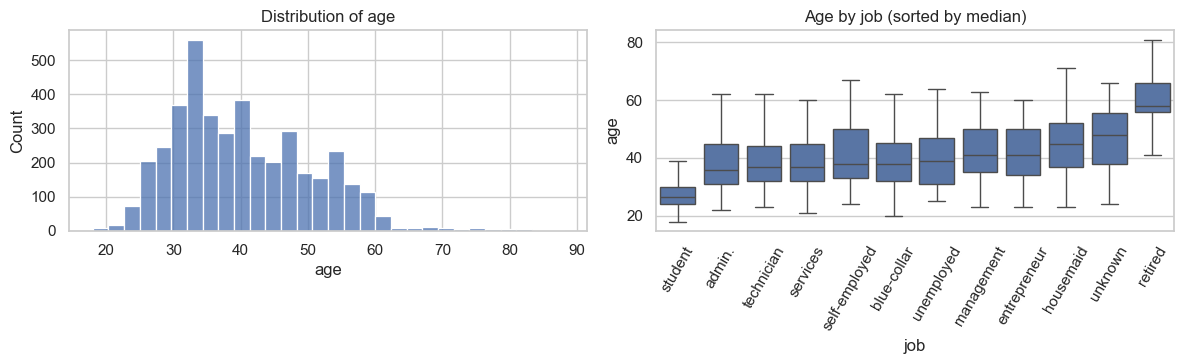

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df["age"], bins=30, ax=axes[0])
axes[0].set_title("Distribution of age")
order = df.groupby("job")["age"].median().sort_values().index
sns.boxplot(data=df, x="job", y="age", order=order, ax=axes[1], showfliers=False)
axes[1].set_title("Age by job (sorted by median)")
axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()

Job clearly shifts the age distribution (students young, retired old), so the profile carries real information about age.

### 11.3 Train the regression tree

First, a fully grown tree (defaults). Then the depth is chosen by **5-fold cross-validation on the training set** — the test set is not used for any choice, so it remains a fair final check.

In [36]:
reg_tree_full = DecisionTreeRegressor(random_state=RANDOM_STATE).fit(Xr_train, yr_train)
print("Fully grown regression tree: depth =", reg_tree_full.get_depth(), "| leaves =", reg_tree_full.get_n_leaves())

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
depth_scores = {}
for depth in range(1, 11):
    scores = cross_val_score(DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE),
                             Xr_train, yr_train, cv=cv, scoring="r2")
    depth_scores[depth] = scores.mean()

best_reg_depth = max(depth_scores, key=depth_scores.get)
print("\nMean 5-fold CV R² by max_depth (training data only):")
print(pd.Series(depth_scores, name="CV R²").round(4).to_string())
print("\nChosen max_depth =", best_reg_depth)

Fully grown regression tree: depth = 23 | leaves = 714



Mean 5-fold CV R² by max_depth (training data only):
1     0.1642
2     0.3094
3     0.3414
4     0.3346
5     0.3503
6     0.3499
7     0.3411
8     0.3357
9     0.3101
10    0.3048

Chosen max_depth = 5


In [37]:
reg_tree = DecisionTreeRegressor(max_depth=best_reg_depth, random_state=RANDOM_STATE)
reg_tree.fit(Xr_train, yr_train)

print("Criterion:", reg_tree.criterion)
print("Depth:", reg_tree.get_depth(), "| Leaves:", reg_tree.get_n_leaves())
print("Distinct predicted values (one per leaf):", np.unique(reg_tree.predict(Xr_train)).size)

Criterion: squared_error
Depth: 5 | Leaves: 31
Distinct predicted values (one per leaf): 30


### 11.4 Predictions of the regression tree

A regression-tree leaf predicts the **mean target value of its training rows**. So every client who lands in the same leaf gets the same predicted age.

In [38]:
yr_pred = reg_tree.predict(Xr_test)
reg_examples = Xr_test_raw.head(10).copy()
reg_examples["actual_age"] = yr_test.head(10).values
reg_examples["predicted_age"] = yr_pred[:10].round(1)
reg_examples["error"] = (reg_examples["predicted_age"] - reg_examples["actual_age"]).round(1)
reg_examples

,job,marital,education,default,housing,loan,actual_age,predicted_age,error
889,admin.,divorced,university.degree,no,no,no,48,41.5,-6.5
2669,services,married,basic.9y,no,no,yes,35,41.5,6.5
2707,housemaid,divorced,basic.4y,no,yes,no,56,47.6,-8.4
2258,admin.,single,university.degree,no,no,no,29,33.0,4.0
2514,admin.,married,high.school,no,no,no,62,41.5,-20.5
1829,entrepreneur,married,basic.9y,no,no,yes,54,41.5,-12.5
2335,admin.,single,unknown,no,yes,yes,41,33.0,-8.0
2314,blue-collar,married,professional.course,no,no,yes,40,37.6,-2.4
438,blue-collar,married,unknown,no,yes,no,43,37.6,-5.4
3676,technician,married,professional.course,no,no,yes,48,41.5,-6.5


### 11.5 Regression tree visualisation

Each box shows the split, the `squared_error` (the MSE of the node — its "impurity"), the number of samples, and `value` = the mean age of the node, which is the prediction if the node is a leaf.

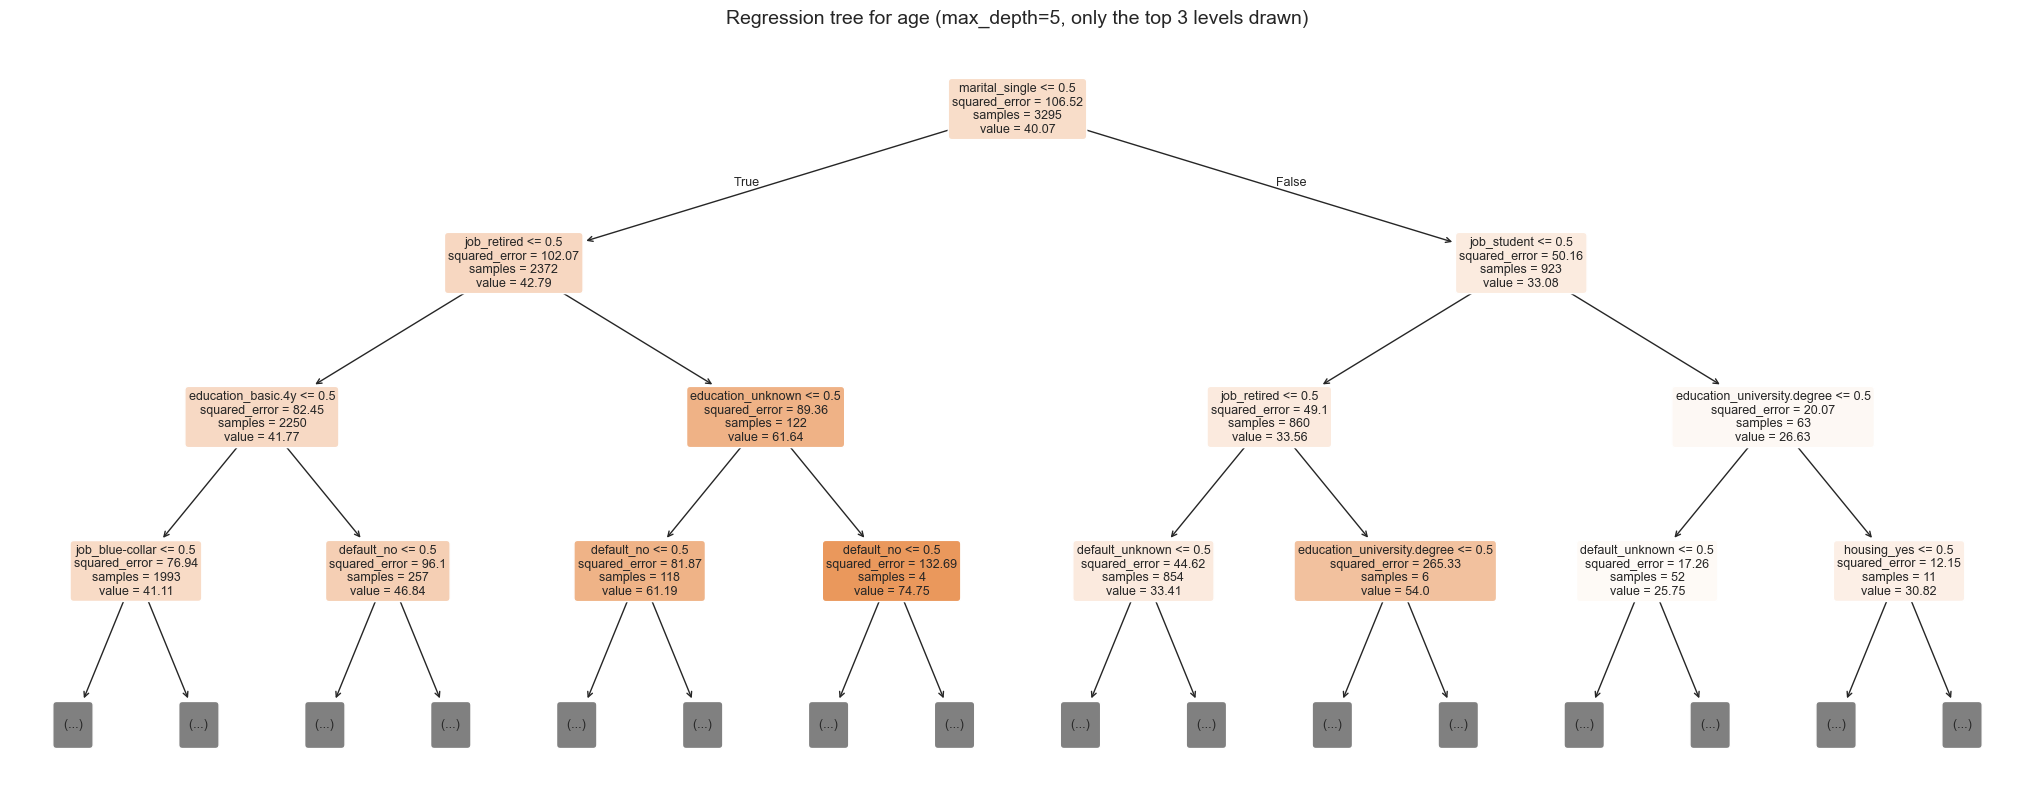

|--- marital_single <= 0.50
|   |--- job_retired <= 0.50
|   |   |--- education_basic.4y <= 0.50
|   |   |   |--- job_blue-collar <= 0.50
|   |   |   |   |--- education_unknown <= 0.50
|   |   |   |   |   |--- value: [41.49]
|   |   |   |   |--- education_unknown >  0.50
|   |   |   |   |   |--- value: [47.50]
|   |   |   |--- job_blue-collar >  0.50
|   |   |   |   |--- default_no <= 0.50
|   |   |   |   |   |--- value: [41.53]
|   |   |   |   |--- default_no >  0.50
|   |   |   |   |   |--- value: [37.61]
|   |   |--- education_basic.4y >  0.50
|   |   |   |--- default_no <= 0.50
|   |   |   |   |--- marital_married <= 0.50
|   |   |   |   |   |--- value: [57.00]
|   |   |   |   |--- marital_married >  0.50
|   |   |   |   |   |--- value: [47.92]
|   |   |   |--- default_no >  0.50
|   |   |   |   |--- job_blue-collar <= 0.50
|   |   |   |   |   |--- value: [47.60]
|   |   |   |   |--- job_blue-collar >  0.50
|   |   |   |   |   |--- value: [43.69]
|   |--- job_retired >  0.50
|   | 

In [39]:
fig, ax = plt.subplots(figsize=(26, 10))
plot_tree(reg_tree, max_depth=3, feature_names=list(Xr_train.columns), filled=True, rounded=True,
          fontsize=9, precision=2, ax=ax)
ax.set_title(f"Regression tree for age (max_depth={best_reg_depth}"
             + (", only the top 3 levels drawn)" if best_reg_depth > 3 else ")"), fontsize=14)
plt.show()

print(export_text(reg_tree, feature_names=list(Xr_train.columns), decimals=2))

## 12. Attribute Selection for Regression — *Evidence for Outcome 6*

For a numeric target there are no classes, so Gini and entropy **cannot** be used. A regression tree measures node impurity by how spread out the target values are around the node's prediction (its mean $\bar{y}_D$):

**Mean Squared Error (node impurity)** — this is the **variance** of the target in the node:
$$MSE(D) = \frac{1}{|D|}\sum_{i \in D} (y_i - \bar{y}_D)^2$$

**Split quality = variance (MSE) reduction** — how much the weighted error falls after splitting $D$ into left $L$ and right $R$:
$$\Delta = MSE(D) - \left(\frac{|L|}{|D|} MSE(L) + \frac{|R|}{|D|} MSE(R)\right)$$

Because each leaf predicts its mean, the weighted child MSE is exactly the **squared prediction error** the tree would make on the training rows after the split. Choosing the maximum $\Delta$ therefore means choosing the split that **reduces prediction error the most**. The algorithm is the same greedy CART search as for classification — only the impurity function changes.

`DecisionTreeRegressor` uses **`criterion="squared_error"`** by default (the regression tree above used it).

### 12.1 Root node MSE and a search over all splits

In [40]:
def node_mse(values):
    return np.mean((values - values.mean()) ** 2)


yr_train_arr = yr_train.to_numpy()
parent_mse = node_mse(yr_train_arr)
print(f"Root node: {len(yr_train_arr)} rows, mean age = {yr_train_arr.mean():.3f}, MSE = variance = {parent_mse:.3f}")
print(f"sklearn root-node impurity (squared_error) = {reg_tree.tree_.impurity[0]:.3f}\n")

split_rows = []
for col in Xr_train.columns:                     # every encoded column is 0/1, so threshold = 0.5
    goes_left = Xr_train[col].to_numpy() <= 0.5
    left, right = yr_train_arr[goes_left], yr_train_arr[~goes_left]
    if len(left) == 0 or len(right) == 0:
        continue
    weighted_child_mse = (len(left) * node_mse(left) + len(right) * node_mse(right)) / len(yr_train_arr)
    split_rows.append({"split": f"{col} <= 0.5", "n_left": len(left), "n_right": len(right),
                       "mean_age_left": left.mean(), "mean_age_right": right.mean(),
                       "weighted_child_MSE": weighted_child_mse,
                       "MSE_reduction": parent_mse - weighted_child_mse})

regression_split_search = pd.DataFrame(split_rows).sort_values("MSE_reduction", ascending=False)
regression_split_search.head(8).round(3)

Root node: 3295 rows, mean age = 40.069, MSE = variance = 106.523
sklearn root-node impurity (squared_error) = 106.523



,split,n_left,n_right,mean_age_left,mean_age_right,weighted_child_MSE,MSE_reduction
14,marital_single <= 0.5,2372,923,42.788,33.083,87.532,18.991
5,job_retired <= 0.5,3167,128,39.212,61.281,88.338,18.185
13,marital_married <= 0.5,1298,1997,36.653,42.290,98.934,7.589
16,education_basic.4y <= 0.5,2952,343,39.140,48.070,99.086,7.437
12,marital_divorced <= 0.5,2928,367,39.379,45.575,102.724,3.799
8,job_student <= 0.5,3229,66,40.343,26.682,102.860,3.663
24,default_no <= 0.5,628,2667,43.635,39.230,103.529,2.994
25,default_unknown <= 0.5,2667,628,39.230,43.635,103.529,2.994


In [41]:
reg_feature_names = list(Xr_train.columns)
print("Best split by my MSE-reduction search:", regression_split_search.iloc[0]["split"])
print("Root split chosen by sklearn         :", reg_feature_names[reg_tree.tree_.feature[0]], "<=",
      round(reg_tree.tree_.threshold[0], 2))
left_child, right_child = reg_tree.tree_.children_left[0], reg_tree.tree_.children_right[0]
print("sklearn weighted child MSE           :", round(
    (reg_tree.tree_.n_node_samples[left_child] * reg_tree.tree_.impurity[left_child]
     + reg_tree.tree_.n_node_samples[right_child] * reg_tree.tree_.impurity[right_child]) / len(yr_train_arr), 3))

Best split by my MSE-reduction search: marital_single <= 0.5
Root split chosen by sklearn         : marital_single <= 0.5
sklearn weighted child MSE           : 87.532


My manual variance-reduction search and scikit-learn choose the **same root split**: separating **single** clients (mean age ≈ 33) from married/divorced clients (mean age ≈ 43) removes the most squared error (MSE falls from 106.5 to 87.5). `job_retired` (mean age ≈ 61 vs 39) is a very close second — it affects fewer people, so its size-weighted reduction is slightly smaller.

### 12.2 Changing the regression criterion

| Criterion | Node impurity | Leaf prediction |
|---|---|---|
| `squared_error` (default) | MSE / variance | mean |
| `friedman_mse` | MSE with Friedman's improvement score for choosing splits | mean |
| `absolute_error` | mean absolute error around the median | **median** (robust to outliers) |
| `poisson` | Poisson deviance (for positive counts/rates) | mean |

In [42]:
def regression_summary(model, X_tr, y_tr, X_te, y_te):
    pred = model.predict(X_te)
    return {"Depth": model.get_depth(), "Leaves": model.get_n_leaves(),
            "Train R²": r2_score(y_tr, model.predict(X_tr)),
            "Test R²": r2_score(y_te, pred),
            "Test RMSE": np.sqrt(mean_squared_error(y_te, pred))}


reg_criterion_rows = []
for criterion in ["squared_error", "friedman_mse", "absolute_error", "poisson"]:
    model = DecisionTreeRegressor(criterion=criterion, max_depth=best_reg_depth, random_state=RANDOM_STATE)
    model.fit(Xr_train, yr_train)
    row = {"Criterion": criterion,
           "Root split": f"{reg_feature_names[model.tree_.feature[0]]} <= {model.tree_.threshold[0]:.1f}"}
    row.update(regression_summary(model, Xr_train, yr_train, Xr_test, yr_test))
    reg_criterion_rows.append(row)

regression_criterion_comparison = pd.DataFrame(reg_criterion_rows)
regression_criterion_comparison.round(4)

,Criterion,Root split,Depth,Leaves,Train R²,Test R²,Test RMSE
0,squared_error,marital_single <= 0.5,5,31,0.3858,0.3227,8.4561
1,friedman_mse,marital_single <= 0.5,5,31,0.3858,0.3227,8.4561
2,absolute_error,marital_single <= 0.5,5,30,0.3608,0.2952,8.6258
3,poisson,marital_single <= 0.5,5,30,0.3856,0.3252,8.4401


All four criteria choose the same root split. `friedman_mse` gives exactly the same tree as `squared_error` here (with 0/1 features its improvement score ranks the splits identically); `absolute_error` optimises a different loss (predicting medians), so its R²/RMSE — which are squared-error metrics — are usually slightly worse even when its trees are reasonable. The default `squared_error` directly minimises the quantity that RMSE measures.

## 13. Evaluating the Regression Tree: R² and RMSE — *Evidence for Outcome 7*

**R² (coefficient of determination)**
$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$
- *What it measures:* the fraction of the target's variance that the model explains, compared with always predicting the mean.
- *Interpretation:* 1 = perfect; 0 = no better than the mean; **negative** = worse than the mean (possible on test data).
- *Limitations:* unitless, so it does not say how large errors are in years; it depends on how variable the test target is; a high R² does not prove the model is unbiased or causal; it can be inflated on training data by overfitting.

**RMSE (root mean squared error)**
$$RMSE = \sqrt{\frac{1}{n}\sum_i (y_i - \hat{y}_i)^2}$$
- *What it measures:* the typical size of a prediction error.
- *Units:* the **same unit as the target** — here, **years of age**.
- *Interpretation:* lower is better; because errors are squared, large mistakes are penalised heavily. Compare it with the target's standard deviation (the RMSE of always predicting the mean).

In [43]:
mean_model = DummyRegressor(strategy="mean").fit(Xr_train, yr_train)

reg_eval_rows = []
for name, model in [("Always predict mean age (baseline)", mean_model),
                    (f"Regression tree, max_depth={best_reg_depth} (CV-chosen)", reg_tree),
                    ("Regression tree, fully grown", reg_tree_full)]:
    for split_name, X_part, y_part in [("train", Xr_train, yr_train), ("test", Xr_test, yr_test)]:
        pred = model.predict(X_part)
        reg_eval_rows.append({"Model": name, "Data": split_name,
                              "R²": r2_score(y_part, pred),
                              "RMSE (years)": np.sqrt(mean_squared_error(y_part, pred))})

regression_evaluation = pd.DataFrame(reg_eval_rows)
regression_evaluation.round(4)

,Model,Data,R²,RMSE (years)
0,Always predict mean age (baseline),train,0.0000,10.3210
1,Always predict mean age (baseline),test,-0.0005,10.2770
2,"Regression tree, max_depth=5 (CV-chosen)",train,0.3858,8.0886
3,"Regression tree, max_depth=5 (CV-chosen)",test,0.3227,8.4561
4,"Regression tree, fully grown",train,0.5477,6.9410
5,"Regression tree, fully grown",test,0.1920,9.2359


In [44]:
# Verify r2_score and RMSE by computing them directly from the formulas
residuals = yr_test.to_numpy() - yr_pred
ss_res = np.sum(residuals ** 2)
ss_tot = np.sum((yr_test.to_numpy() - yr_test.mean()) ** 2)
print(f"Manual R²   = 1 - {ss_res:.1f} / {ss_tot:.1f} = {1 - ss_res / ss_tot:.4f}   | r2_score()          = {r2_score(yr_test, yr_pred):.4f}")
print(f"Manual RMSE = sqrt({np.mean(residuals ** 2):.3f}) = {np.sqrt(np.mean(residuals ** 2)):.4f} years | sqrt(mean_squared_error) = {np.sqrt(mean_squared_error(yr_test, yr_pred)):.4f}")
print(f"Standard deviation of test ages = {yr_test.std(ddof=0):.4f} years (the RMSE of always predicting the mean)")

Manual R²   = 1 - 58920.2 / 86987.7 = 0.3227   | r2_score()          = 0.3227
Manual RMSE = sqrt(71.505) = 8.4561 years | sqrt(mean_squared_error) = 8.4561
Standard deviation of test ages = 10.2746 years (the RMSE of always predicting the mean)


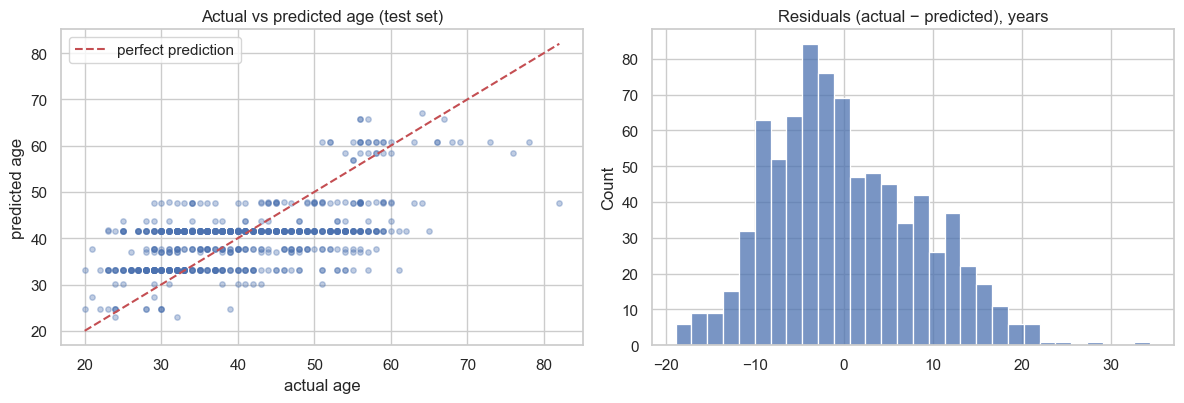

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].scatter(yr_test, yr_pred, alpha=0.35, s=15)
lims = [yr_test.min(), yr_test.max()]
axes[0].plot(lims, lims, "r--", label="perfect prediction")
axes[0].set_xlabel("actual age")
axes[0].set_ylabel("predicted age")
axes[0].set_title("Actual vs predicted age (test set)")
axes[0].legend()
sns.histplot(residuals, bins=30, ax=axes[1])
axes[1].set_title("Residuals (actual − predicted), years")
plt.tight_layout()
plt.show()

**Interpretation**
- The CV-chosen tree explains roughly a third of the variance in age on unseen clients (test R² ≈ 0.32) and reduces the typical error from about 10.3 years (always predicting the mean age) to about 8.5 years (test RMSE). This is a moderate result, which is what we expected: the profile tells us a lot about some groups (retired, students) but little about the age of, say, an admin employee.
- The **fully grown** tree has a much higher training R² but a **lower test R²** — the same overfitting pattern seen in classification.
- The predicted values form **horizontal bands** in the scatter plot: a regression tree is **piece-wise constant**, predicting one mean value per leaf. Section 14 improves on this with piece-wise *models*.

## 14. Model Trees: Piece-wise Models after Decision Splits — *Evidence for Outcome 8*

### 14.1 Concept

A decision tree's splits partition the feature space into **non-overlapping regions** (one region per leaf). What happens *inside* each region is a separate choice:

| | Ordinary regression tree (`DecisionTreeRegressor`) | Model tree (e.g. M5 / M5P, LMT) |
|---|---|---|
| Splits | yes | yes |
| Model in each leaf | a **constant** (the mean of the leaf) | a **separate model**, typically a **linear regression** fitted to the leaf's rows |
| Overall shape | piece-wise **constant** (a staircase) | piece-wise **linear** (connected or disconnected line segments) |

**Important:** scikit-learn's `DecisionTreeRegressor` does **not** fit linear models in its leaves — it only predicts leaf means. scikit-learn has no built-in model-tree class, so below I build a simple model tree myself in two clear steps:

1. **Split:** fit a shallow `DecisionTreeRegressor` only to find the regions (its thresholds define the partition).
2. **Fit piece-wise:** fit a separate `LinearRegression` on the training rows of each region (leaf).

To predict, a row is first sent down the tree to find its region (`tree.apply()`), then that region's linear model makes the prediction.

In [46]:
def fit_model_tree(X_tr, y_tr, max_depth, min_samples_leaf):
    # Step 1: a shallow tree defines the regions.  Step 2: one linear model per region (leaf).
    splitter = DecisionTreeRegressor(max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                                     random_state=RANDOM_STATE).fit(X_tr, y_tr)
    leaf_of_row = splitter.apply(X_tr)
    leaf_models = {}
    for leaf in np.unique(leaf_of_row):
        in_leaf = leaf_of_row == leaf
        leaf_models[leaf] = LinearRegression().fit(X_tr[in_leaf], y_tr[in_leaf])
    return splitter, leaf_models


def predict_model_tree(splitter, leaf_models, X_new):
    leaf_of_row = splitter.apply(X_new)
    predictions = np.empty(len(X_new))
    for leaf, linear_model in leaf_models.items():
        in_leaf = leaf_of_row == leaf
        if in_leaf.any():
            predictions[in_leaf] = linear_model.predict(X_new[in_leaf])
    return predictions

### 14.2 A one-feature illustration on real columns: `nr.employed` as a function of `euribor3m`

With one input feature, the regions are intervals on a line and the difference between a staircase and line segments can be seen directly. I use two genuine (economic) columns of the dataset: the 3-month Euribor interest rate (`euribor3m`, x) and the number of employees in thousands (`nr.employed`, y). Both describe the economy at the time of the call, and they move together. This is a **descriptive illustration of the technique**, not a causal or business claim.

In [47]:
X_pw = df[["euribor3m"]]
y_pw = df["nr.employed"]
Xpw_train, Xpw_test, ypw_train, ypw_test = train_test_split(X_pw, y_pw, test_size=0.2, random_state=RANDOM_STATE)

global_line = LinearRegression().fit(Xpw_train, ypw_train)
step_tree = DecisionTreeRegressor(max_depth=1, min_samples_leaf=30, random_state=RANDOM_STATE).fit(Xpw_train, ypw_train)
pw_splitter, pw_leaf_models = fit_model_tree(Xpw_train, ypw_train.to_numpy(), max_depth=1, min_samples_leaf=30)

threshold = pw_splitter.tree_.threshold[0]
print(f"Decision split found by the tree:  euribor3m <= {threshold:.4f}\n")
for leaf, lm in pw_leaf_models.items():
    in_region = pw_splitter.apply(Xpw_train) == leaf
    region = f"Region 1: euribor3m <= {threshold:.3f}" if leaf == pw_splitter.tree_.children_left[0] \
        else f"Region 2: euribor3m >  {threshold:.3f}"
    print(f"{region} | {in_region.sum():4d} training rows | "
          f"regression-tree prediction = {ypw_train[in_region].mean():.1f} (constant) | "
          f"model-tree line: nr.employed = {lm.intercept_:.2f} + {lm.coef_[0]:.2f} * euribor3m")

Decision split found by the tree:  euribor3m <= 2.5700

Region 1: euribor3m <= 2.570 | 1078 training rows | regression-tree prediction = 5069.3 (constant) | model-tree line: nr.employed = 4906.69 + 140.42 * euribor3m
Region 2: euribor3m >  2.570 | 2217 training rows | regression-tree prediction = 5213.5 (constant) | model-tree line: nr.employed = 5056.67 + 32.60 * euribor3m


In [48]:
pw_splitter2, pw_leaf_models2 = fit_model_tree(Xpw_train, ypw_train.to_numpy(), max_depth=2, min_samples_leaf=30)
step_tree2 = DecisionTreeRegressor(max_depth=2, min_samples_leaf=30, random_state=RANDOM_STATE).fit(Xpw_train, ypw_train)

piecewise_rows = []
for name, pred in [
        ("Global linear regression (1 line, no split)", global_line.predict(Xpw_test)),
        ("Regression tree, depth 1 (2 constants)", step_tree.predict(Xpw_test)),
        ("Model tree, depth 1 (2 lines)", predict_model_tree(pw_splitter, pw_leaf_models, Xpw_test)),
        ("Regression tree, depth 2 (4 constants)", step_tree2.predict(Xpw_test)),
        ("Model tree, depth 2 (4 lines)", predict_model_tree(pw_splitter2, pw_leaf_models2, Xpw_test))]:
    piecewise_rows.append({"Model": name, "Test R²": r2_score(ypw_test, pred),
                           "Test RMSE (thousand employees)": np.sqrt(mean_squared_error(ypw_test, pred))})
piecewise_1d = pd.DataFrame(piecewise_rows)
piecewise_1d.round(4)

,Model,Test R²,Test RMSE (thousand employees)
0,"Global linear regression (1 line, no split)",0.8850,24.7890
1,"Regression tree, depth 1 (2 constants)",0.8340,29.7857
2,"Model tree, depth 1 (2 lines)",0.9306,19.2669
3,"Regression tree, depth 2 (4 constants)",0.9699,12.6761
4,"Model tree, depth 2 (4 lines)",0.9718,12.2723


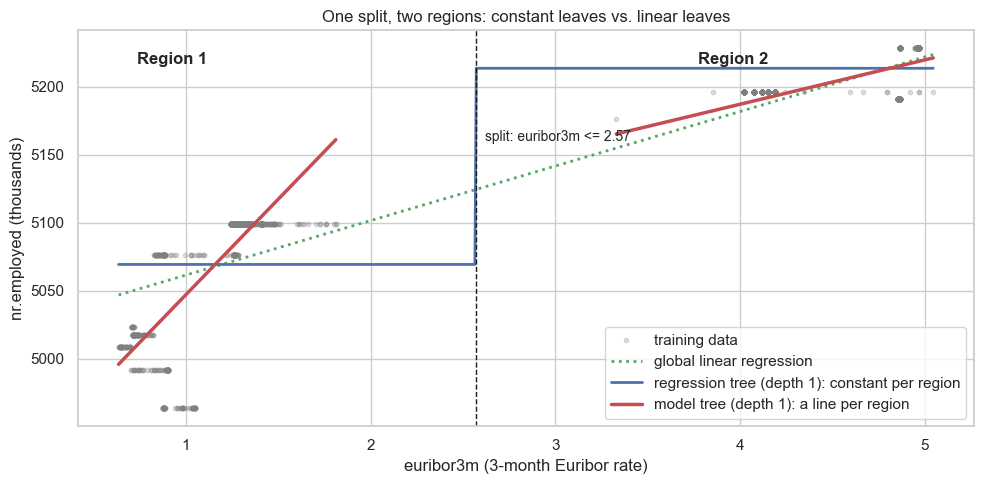

In [49]:
grid = pd.DataFrame({"euribor3m": np.linspace(X_pw["euribor3m"].min(), X_pw["euribor3m"].max(), 600)})
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(Xpw_train["euribor3m"], ypw_train, s=10, alpha=0.25, color="grey", label="training data")
ax.plot(grid["euribor3m"], global_line.predict(grid), "g:", lw=2, label="global linear regression")
ax.plot(grid["euribor3m"], step_tree.predict(grid), "b-", lw=2, label="regression tree (depth 1): constant per region")
# draw each region's line only over the x-range where that region has training data (no extrapolation)
train_leaf = pw_splitter.apply(Xpw_train)
for k, (leaf, lm) in enumerate(pw_leaf_models.items()):
    x_region = Xpw_train["euribor3m"][train_leaf == leaf]
    x_line = pd.DataFrame({"euribor3m": np.linspace(x_region.min(), x_region.max(), 100)})
    ax.plot(x_line["euribor3m"], lm.predict(x_line), "r-", lw=2.5,
            label="model tree (depth 1): a line per region" if k == 0 else None)
ax.axvline(threshold, color="k", ls="--", lw=1)
ax.text(threshold + 0.05, 5160, f"split: euribor3m <= {threshold:.2f}", fontsize=10)
ax.text(X_pw["euribor3m"].min() + 0.1, ax.get_ylim()[1] - 25, "Region 1", fontsize=12, weight="bold")
ax.text(threshold + 1.2, ax.get_ylim()[1] - 25, "Region 2", fontsize=12, weight="bold")
ax.set_xlabel("euribor3m (3-month Euribor rate)")
ax.set_ylabel("nr.employed (thousands)")
ax.set_title("One split, two regions: constant leaves vs. linear leaves")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**What the plot shows:** the tree finds one threshold on `euribor3m` and creates two regions. The ordinary regression tree (blue) predicts one flat value per region. The model tree (red) uses the *same split* but fits its own line in each region, so it follows the trend within each region. Neither a single global line (green) nor a single split with constants captures the relationship as well as the piece-wise linear model, as the test R²/RMSE table confirms. (Because `nr.employed` is a quarterly indicator it only takes a few distinct values, which is why the data forms horizontal bands. There are also almost no calls with `euribor3m` between about 1.8 and 3.9, so each red line is drawn only over the range where its region has data.)

With a second level of splits (depth 2, four regions) the constant-leaf tree already follows the shape quite well, and the advantage of linear leaves becomes small (R² 0.970 vs 0.972): piece-wise models give the biggest benefit when the tree is kept shallow.

### 14.3 Model tree on the main regression task (age)

The same two-step model tree is applied to the age task of Section 11 (one-hot profile features). A linear model is fitted inside every region and compared with an ordinary regression tree of the same depth and with a single global linear regression.

In [50]:
Xr_train_np, Xr_test_np = Xr_train.to_numpy(), Xr_test.to_numpy()
yr_train_np = yr_train.to_numpy()

model_tree_rows = [{"Model": "Global linear regression (no split)", "Regions": 1,
                    "Test R²": r2_score(yr_test, LinearRegression().fit(Xr_train_np, yr_train_np).predict(Xr_test_np))}]
for depth in [1, 2, 3]:
    plain = DecisionTreeRegressor(max_depth=depth, min_samples_leaf=50, random_state=RANDOM_STATE).fit(Xr_train_np, yr_train_np)
    splitter, leaf_models = fit_model_tree(Xr_train_np, yr_train_np, max_depth=depth, min_samples_leaf=50)
    model_tree_rows.append({"Model": f"Regression tree, depth {depth} (constant leaves)", "Regions": plain.get_n_leaves(),
                            "Test R²": r2_score(yr_test, plain.predict(Xr_test_np))})
    model_tree_rows.append({"Model": f"Model tree, depth {depth} (linear leaves)", "Regions": len(leaf_models),
                            "Test R²": r2_score(yr_test, predict_model_tree(splitter, leaf_models, Xr_test_np))})

model_tree_age = pd.DataFrame(model_tree_rows)
model_tree_age.round(4)

,Model,Regions,Test R²
0,Global linear regression (no split),1,0.3478
1,"Regression tree, depth 1 (constant leaves)",2,0.1576
2,"Model tree, depth 1 (linear leaves)",2,0.3451
3,"Regression tree, depth 2 (constant leaves)",4,0.2890
4,"Model tree, depth 2 (linear leaves)",4,0.3402
5,"Regression tree, depth 3 (constant leaves)",7,0.3155
6,"Model tree, depth 3 (linear leaves)",7,0.3291


**Interpretation:** with the same number of regions, a model tree is much more accurate than a constant-leaf tree when the tree is shallow, because each region still gets to use *all* the other profile features through its linear model. As the tree deepens, the plain tree catches up (it creates the regions itself) and the linear models have fewer rows to learn from, so the gain shrinks. On this dataset the model tree is roughly on par with a single global linear model — honest evidence that piece-wise models help most where the relationship really changes between regions (as in 14.2), not automatically everywhere.

**Limitations of this simple model tree:** real model-tree algorithms such as M5 choose splits *knowing* that linear models will be fitted afterwards, prune using the linear models' errors and smooth predictions between neighbouring leaves; this demonstration uses ordinary CART splits followed by per-leaf least squares.

## 15. Decision Tree Pruning — *Evidence for Outcome 9*

A fully grown tree keeps splitting until its leaves are pure, so it memorises noise in the training data: **overfitting**. Two families of techniques control this:

| Type | Technique | scikit-learn parameter | Effect |
|---|---|---|---|
| **Pre-pruning** (early stopping — stop growing) | maximum depth | `max_depth` | no path longer than *d* questions |
| | minimum samples to split | `min_samples_split` | a node with fewer rows becomes a leaf |
| | minimum samples in a leaf | `min_samples_leaf` | a split is rejected if a child would be too small |
| | (also `max_leaf_nodes`, `min_impurity_decrease`) | | |
| **Post-pruning** (grow fully, then cut back) | **minimal cost-complexity pruning** | `ccp_alpha` | removes the branches that add the least impurity reduction per extra leaf |

**Cost-complexity pruning:** for a tree $T$ with $|T|$ leaves and total leaf impurity $R(T)$ (weighted by the fraction of samples), minimise
$$R_\alpha(T) = R(T) + \alpha\,|T|$$
$\alpha = 0$ keeps the full tree; larger $\alpha$ charges more for each leaf, so weak branches are collapsed. `cost_complexity_pruning_path()` returns the exact sequence of $\alpha$ values at which a branch gets pruned.

### 15.1 The unpruned tree (overfitting)

In [51]:
unpruned = tree_clf    # the fully grown baseline tree from Section 7
print("UNPRUNED tree (defaults: no depth limit, min_samples_split=2, min_samples_leaf=1)")
print(f"  depth = {unpruned.get_depth()}, leaves = {unpruned.get_n_leaves()}")
print(f"  training accuracy = {accuracy_score(y_train, unpruned.predict(X_train)):.4f}")
print(f"  test accuracy     = {accuracy_score(y_test, unpruned.predict(X_test)):.4f}")

UNPRUNED tree (defaults: no depth limit, min_samples_split=2, min_samples_leaf=1)
  depth = 25, leaves = 436
  training accuracy = 1.0000
  test accuracy     = 0.8265


### 15.2 How depth drives overfitting

Training accuracy rises steadily as depth grows, but test accuracy peaks early and then falls — the classic overfitting curve. (The test set is used here only to *illustrate*; parameters below are chosen by cross-validation on the training set.)

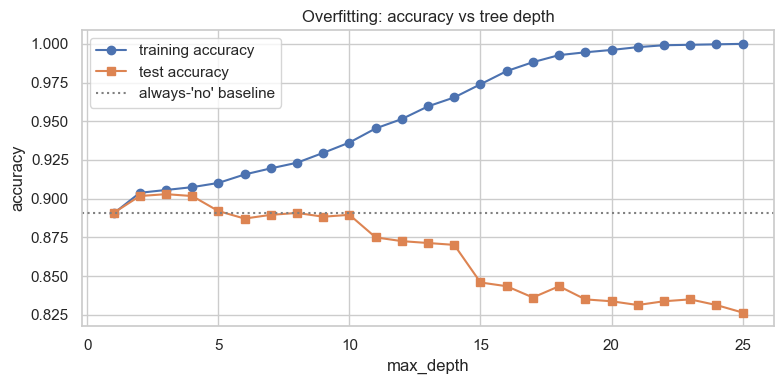

In [52]:
depths = range(1, unpruned.get_depth() + 1)
train_curve, test_curve = [], []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_curve.append(accuracy_score(y_train, model.predict(X_train)))
    test_curve.append(accuracy_score(y_test, model.predict(X_test)))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depths, train_curve, "o-", label="training accuracy")
ax.plot(depths, test_curve, "s-", label="test accuracy")
ax.axhline(accuracy_score(y_test, majority_pred), color="grey", ls=":", label="always-'no' baseline")
ax.set_xlabel("max_depth")
ax.set_ylabel("accuracy")
ax.set_title("Overfitting: accuracy vs tree depth")
ax.legend()
plt.tight_layout()
plt.show()

### 15.3 Pre-pruning (stopping) techniques

Each hyper-parameter is tuned by **5-fold stratified cross-validation on the training set** (`GridSearchCV`, accuracy), and each is compared with the unpruned tree.

In [53]:
cv_strat = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
pre_pruning_grids = {
    "max_depth": [2, 3, 4, 5, 6, 8, 10, 15],
    "min_samples_split": [2, 10, 25, 50, 100, 200, 400],
    "min_samples_leaf": [1, 5, 10, 20, 40, 80, 150],
}

pre_pruned_models = {}
for param, values in pre_pruning_grids.items():
    search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), {param: values},
                          cv=cv_strat, scoring="accuracy").fit(X_train, y_train)
    pre_pruned_models[f"{param}={search.best_params_[param]}"] = search.best_estimator_
    print(f"{param:18s}: best value = {search.best_params_[param]:>4}  (mean CV accuracy {search.best_score_:.4f})")

max_depth         : best value =    2  (mean CV accuracy 0.9032)


min_samples_split : best value =  200  (mean CV accuracy 0.9014)


min_samples_leaf  : best value =   80  (mean CV accuracy 0.9035)


### 15.4 Post-pruning: minimal cost-complexity pruning

Number of candidate alphas on the pruning path: 140
Smallest alphas: [0.       0.000149 0.000149 0.000177 0.000188] ... largest: [0.00175 0.00632 0.032  ]


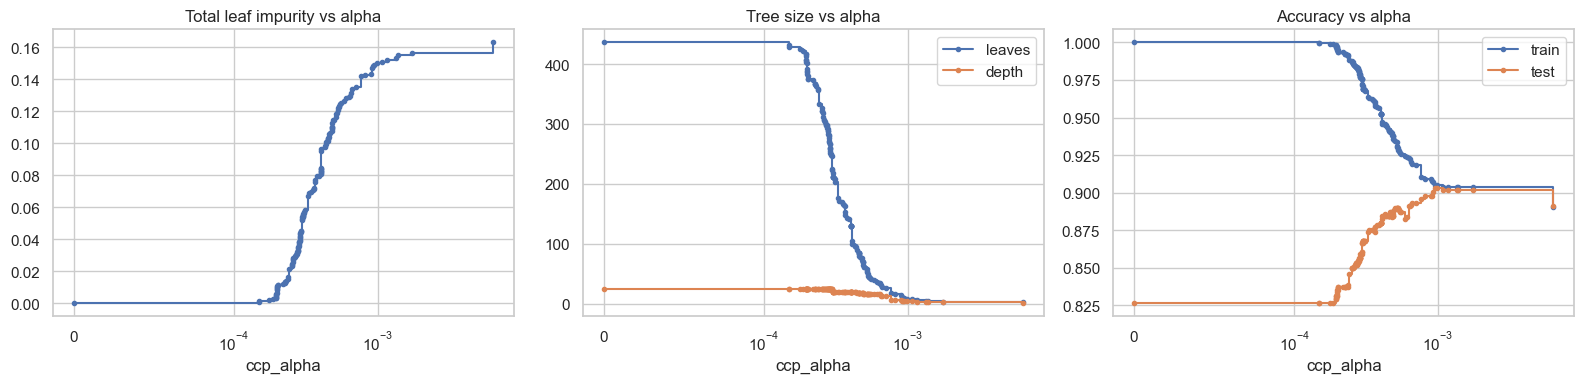

In [54]:
path = unpruned.cost_complexity_pruning_path(X_train, y_train)
ccp_alphas, total_impurities = path.ccp_alphas, path.impurities
print("Number of candidate alphas on the pruning path:", len(ccp_alphas))
print("Smallest alphas:", np.round(ccp_alphas[:5], 6), "... largest:", np.round(ccp_alphas[-3:], 5))

# One tree per alpha (the last alpha prunes everything down to the root, so it is dropped)
alpha_trees = [DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a).fit(X_train, y_train)
               for a in ccp_alphas[:-1]]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(ccp_alphas[:-1], total_impurities[:-1], marker=".", drawstyle="steps-post")
axes[0].set_title("Total leaf impurity vs alpha")
axes[0].set_xlabel("ccp_alpha")
axes[1].plot(ccp_alphas[:-1], [t.get_n_leaves() for t in alpha_trees], marker=".", drawstyle="steps-post", label="leaves")
axes[1].plot(ccp_alphas[:-1], [t.get_depth() for t in alpha_trees], marker=".", drawstyle="steps-post", label="depth")
axes[1].set_title("Tree size vs alpha")
axes[1].set_xlabel("ccp_alpha")
axes[1].legend()
axes[2].plot(ccp_alphas[:-1], [accuracy_score(y_train, t.predict(X_train)) for t in alpha_trees], marker=".",
             drawstyle="steps-post", label="train")
axes[2].plot(ccp_alphas[:-1], [accuracy_score(y_test, t.predict(X_test)) for t in alpha_trees], marker=".",
             drawstyle="steps-post", label="test")
axes[2].set_title("Accuracy vs alpha")
axes[2].set_xlabel("ccp_alpha")
axes[2].legend()
for ax in axes:
    ax.set_xscale("symlog", linthresh=1e-4)
plt.tight_layout()
plt.show()

As $\alpha$ grows the tree shrinks from hundreds of leaves towards a single root, training accuracy falls, and test accuracy first rises (noise branches removed) before eventually dropping (useful structure removed). The best $\alpha$ is chosen by cross-validation **on the training set only**:

In [55]:
ccp_search = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                          {"ccp_alpha": ccp_alphas[:-1]}, cv=cv_strat, scoring="accuracy")
ccp_search.fit(X_train, y_train)
best_alpha = ccp_search.best_params_["ccp_alpha"]
print(f"Best ccp_alpha by 5-fold CV = {best_alpha:.6f} (mean CV accuracy {ccp_search.best_score_:.4f})")

pruned_clf = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=best_alpha).fit(X_train, y_train)
print(f"Pruned tree: depth = {pruned_clf.get_depth()}, leaves = {pruned_clf.get_n_leaves()}")

Best ccp_alpha by 5-fold CV = 0.001746 (mean CV accuracy 0.9032)
Pruned tree: depth = 2, leaves = 3


### 15.5 Unpruned vs pruned

In [56]:
def pruning_row(name, model):
    return {"Model": name, "Depth": model.get_depth(), "Leaves": model.get_n_leaves(),
            "Train Accuracy": accuracy_score(y_train, model.predict(X_train)),
            "Test Accuracy": accuracy_score(y_test, model.predict(X_test)),
            "Test F1 (yes)": f1_score(y_test, model.predict(X_test))}


pruning_table = pd.DataFrame(
    [pruning_row("Unpruned (defaults)", unpruned)]
    + [pruning_row(f"Pre-pruned: {name}", model) for name, model in pre_pruned_models.items()]
    + [pruning_row(f"Post-pruned: ccp_alpha={best_alpha:.5f}", pruned_clf)])
pruning_table.round(4)

,Model,Depth,Leaves,Train Accuracy,Test Accuracy,Test F1 (yes)
0,Unpruned (defaults),25,436,1.0000,0.8265,0.2011
1,Pre-pruned: max_depth=2,2,4,0.9038,0.9017,0.2430
2,Pre-pruned: min_samples_split=200,17,43,0.9044,0.9017,0.2430
3,Pre-pruned: min_samples_leaf=80,13,31,0.9038,0.9017,0.2430
4,Post-pruned: ccp_alpha=0.00175,2,3,0.9038,0.9017,0.2430


In [57]:
side_by_side = pd.DataFrame({
    "Unpruned": [unpruned.get_depth(), unpruned.get_n_leaves(),
                 accuracy_score(y_train, unpruned.predict(X_train)), accuracy_score(y_test, unpruned.predict(X_test))],
    "Pruned (ccp)": [pruned_clf.get_depth(), pruned_clf.get_n_leaves(),
                     accuracy_score(y_train, pruned_clf.predict(X_train)), accuracy_score(y_test, pruned_clf.predict(X_test))],
}, index=["Depth", "Leaves", "Training accuracy", "Testing accuracy"])
side_by_side.round(4)

,Unpruned,Pruned (ccp)
Depth,25.0000,2.0000
Leaves,436.0000,3.0000
Training accuracy,1.0000,0.9038
Testing accuracy,0.8265,0.9017


**Observations:** every tuned stopping rule and cost-complexity pruning improve test accuracy from 0.83 to 0.90 while shrinking the tree from 436 leaves to between 3 and 43. They even make *identical* test predictions: in each of them the only region predicted "yes" is the same group of clients (low `nr.employed` and recently contacted before), so the extra leaves of the `min_samples_split` / `min_samples_leaf` trees only refine probabilities, not the final class. Cross-validation preferred a very small tree because on this imbalanced data most deeper splits did not improve accuracy on held-out folds.

### 15.6 The pruned tree

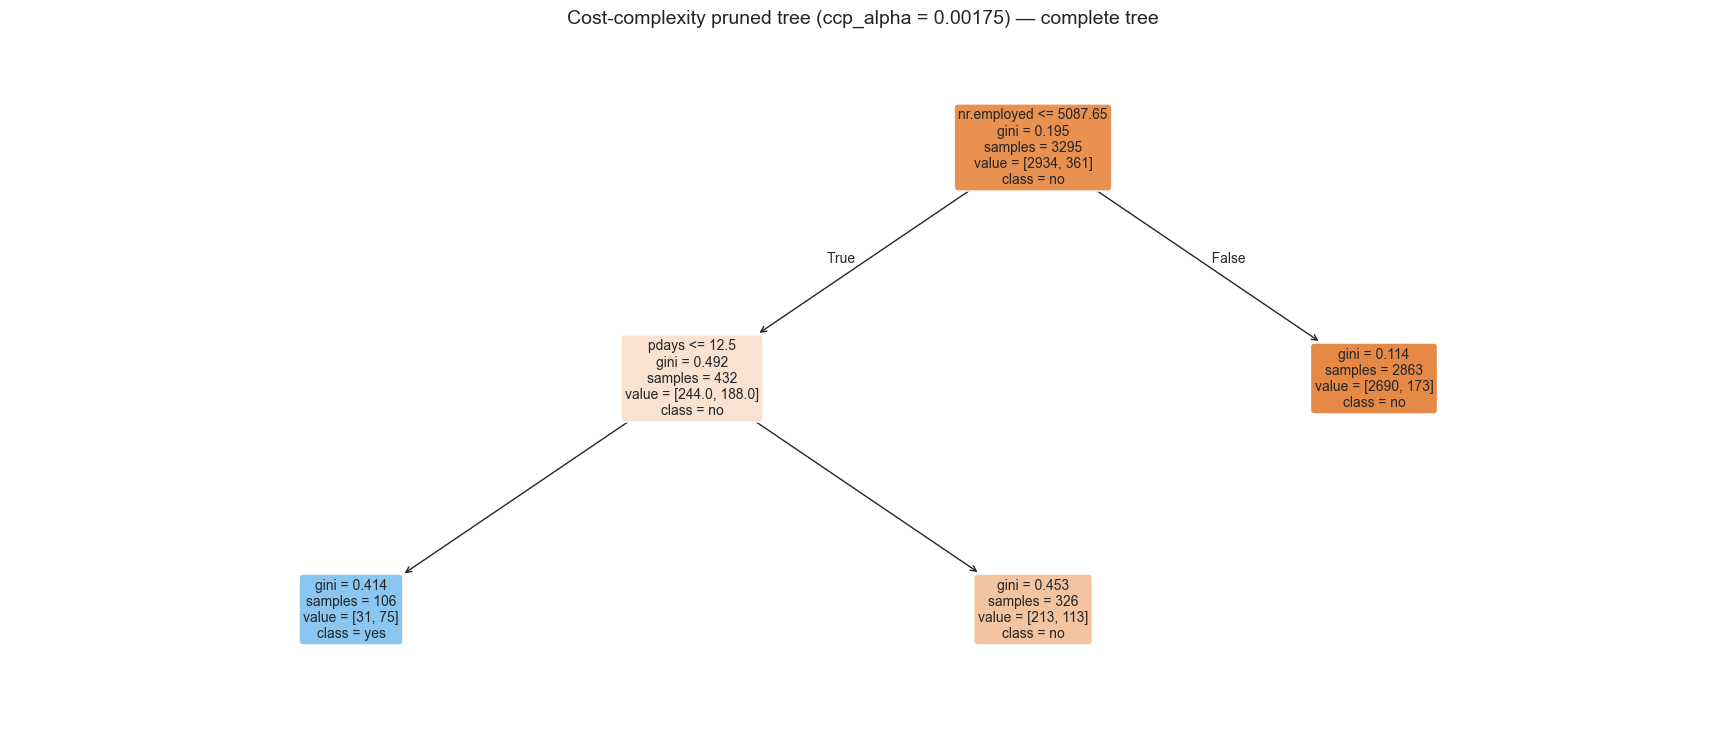

|--- nr.employed <= 5087.65
|   |--- pdays <= 12.50
|   |   |--- weights: [31.00, 75.00] class: 1
|   |--- pdays >  12.50
|   |   |--- weights: [213.00, 113.00] class: 0
|--- nr.employed >  5087.65
|   |--- weights: [2690.00, 173.00] class: 0



In [58]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(pruned_clf, feature_names=feature_names, class_names=CLASS_NAMES, filled=True, rounded=True,
          fontsize=10, ax=ax)
ax.set_title(f"Cost-complexity pruned tree (ccp_alpha = {best_alpha:.5f}) — complete tree", fontsize=14)
plt.show()
print(export_text(pruned_clf, feature_names=feature_names, show_weights=True))

**Reading the pruned tree as rules** (`weights` = training rows [no, yes]):
1. If `nr.employed > 5087.65` (periods of high employment) → predict **no** (only about 6% of these clients subscribed).
2. If `nr.employed <= 5087.65` and `pdays <= 12.5` (client contacted in a previous campaign within the last ~12 days) → predict **yes** (about 71% subscribed).
3. If `nr.employed <= 5087.65` and `pdays > 12.5` (including 999 = never contacted) → predict **no**, although about 35% subscribed — much higher than the overall 11%.

These three rules are simple enough to explain to a marketing team, which is one of the main practical benefits of pruning.

In [59]:
pruned_pred = pruned_clf.predict(X_test)
pruned_proba = pruned_clf.predict_proba(X_test)[:, 1]
print("Pruned tree on the test set:\n")
print(classification_report(y_test, pruned_pred, target_names=CLASS_NAMES, digits=4))
print("Distinct P(yes) values now produced (graded, no longer only 0 or 1):")
print(np.unique(pruned_proba.round(3)))

Pruned tree on the test set:

              precision    recall  f1-score   support

          no     0.9046    0.9946    0.9474       734
         yes     0.7647    0.1444    0.2430        90

    accuracy                         0.9017       824
   macro avg     0.8346    0.5695    0.5952       824
weighted avg     0.8893    0.9017    0.8705       824

Distinct P(yes) values now produced (graded, no longer only 0 or 1):
[0.06  0.347 0.708]


**Why pruning helps**
- **Generalisation:** the deep branches of the unpruned tree fit individual, noisy training rows. Removing them lowers training accuracy but *raises* test accuracy — the model learns general patterns instead of memorising.
- **Simplicity:** the pruned tree is a small set of readable rules instead of hundreds of leaves, which is far easier to explain to a bank manager (or in a viva).
- **Better probabilities:** leaves contain many rows, so `predict_proba` gives graded estimates (e.g. "about 71% chance") instead of 0/1.

**Trade-off to note honestly:** pruning selected purely for *accuracy* on an imbalanced dataset favours predicting "no"; the pruned tree is more precise when it says "yes" but still misses many subscribers. If finding subscribers matters more, one would tune for F1/recall, use `class_weight="balanced"`, or lower the probability threshold — that choice depends on the cost of a call vs the value of a new deposit.

## 16. Final Results

All numbers below are recomputed from the fitted models above on the same held-out test set.

### 16.1 Classification (target `y`, test set, positive class = "yes")

In [60]:
classification_models = [
    ("Always 'no' (baseline)", "-", majority_model, X_train, X_test),
    ("Baseline tree (B, unpruned)", "gini", tree_clf, X_train, X_test),
    ("Entropy tree (B, unpruned)", "entropy", tree_entropy, X_train, X_test),
    ("Tree B, max_depth=5", "gini", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE).fit(X_train, y_train), X_train, X_test),
    ("Tree A (with duration), max_depth=5", "gini", model_A_depth5, X_train_A, X_test_A),
    ("Pruned tree (B, ccp_alpha)", "gini", pruned_clf, X_train, X_test),
]
final_classification = []
for name, criterion, model, X_tr, X_te in classification_models:
    pred = model.predict(X_te)
    final_classification.append({
        "Model": name, "Criterion": criterion,
        "Depth": model.get_depth() if hasattr(model, "get_depth") else 0,
        "Leaves": model.get_n_leaves() if hasattr(model, "get_n_leaves") else 1,
        "Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred), "F1": f1_score(y_test, pred)})
pd.DataFrame(final_classification).round(4)

,Model,Criterion,Depth,Leaves,Accuracy,Precision,Recall,F1
0,Always 'no' (baseline),-,0,1,0.8908,0.0000,0.0000,0.0000
1,"Baseline tree (B, unpruned)",gini,25,436,0.8265,0.2022,0.2000,0.2011
2,"Entropy tree (B, unpruned)",entropy,29,427,0.8398,0.2812,0.3000,0.2903
3,"Tree B, max_depth=5",gini,5,25,0.8920,0.5385,0.0778,0.1359
4,"Tree A (with duration), max_depth=5",gini,5,32,0.9090,0.6190,0.4333,0.5098
5,"Pruned tree (B, ccp_alpha)",gini,2,3,0.9017,0.7647,0.1444,0.2430


### 16.2 Regression (target `age`, test set)

In [61]:
final_regression = [{"Model": "Always predict mean (baseline)", "Criterion": "-", "Depth": 0, "Leaves": 1,
                     "R²": r2_score(yr_test, mean_model.predict(Xr_test)),
                     "RMSE (years)": np.sqrt(mean_squared_error(yr_test, mean_model.predict(Xr_test)))},
                    {"Model": "Regression tree, fully grown", "Criterion": "squared_error",
                     "Depth": reg_tree_full.get_depth(), "Leaves": reg_tree_full.get_n_leaves(),
                     "R²": r2_score(yr_test, reg_tree_full.predict(Xr_test)),
                     "RMSE (years)": np.sqrt(mean_squared_error(yr_test, reg_tree_full.predict(Xr_test)))}]
for row in reg_criterion_rows:
    final_regression.append({"Model": f"Regression tree, max_depth={best_reg_depth}", "Criterion": row["Criterion"],
                             "Depth": row["Depth"], "Leaves": row["Leaves"],
                             "R²": row["Test R²"], "RMSE (years)": row["Test RMSE"]})
mt_splitter, mt_leaf_models = fit_model_tree(Xr_train_np, yr_train_np, max_depth=1, min_samples_leaf=50)
mt_pred = predict_model_tree(mt_splitter, mt_leaf_models, Xr_test_np)
final_regression.append({"Model": "Model tree (linear leaves)", "Criterion": "squared_error splits",
                         "Depth": mt_splitter.get_depth(), "Leaves": mt_splitter.get_n_leaves(),
                         "R²": r2_score(yr_test, mt_pred), "RMSE (years)": np.sqrt(mean_squared_error(yr_test, mt_pred))})
pd.DataFrame(final_regression).round(4)

,Model,Criterion,Depth,Leaves,R²,RMSE (years)
0,Always predict mean (baseline),-,0,1,-0.0005,10.2770
1,"Regression tree, fully grown",squared_error,23,714,0.1920,9.2359
2,"Regression tree, max_depth=5",squared_error,5,31,0.3227,8.4561
3,"Regression tree, max_depth=5",friedman_mse,5,31,0.3227,8.4561
4,"Regression tree, max_depth=5",absolute_error,5,30,0.2952,8.6258
5,"Regression tree, max_depth=5",poisson,5,30,0.3252,8.4401
6,Model tree (linear leaves),squared_error splits,1,2,0.3451,8.3149


### 16.3 Pruning (classification, Model B)

In [62]:
pruning_table[["Model", "Depth", "Leaves", "Train Accuracy", "Test Accuracy"]].round(4)

,Model,Depth,Leaves,Train Accuracy,Test Accuracy
0,Unpruned (defaults),25,436,1.0000,0.8265
1,Pre-pruned: max_depth=2,2,4,0.9038,0.9017
2,Pre-pruned: min_samples_split=200,17,43,0.9044,0.9017
3,Pre-pruned: min_samples_leaf=80,13,31,0.9038,0.9017
4,Post-pruned: ccp_alpha=0.00175,2,3,0.9038,0.9017


## 17. Mapping of the 9 Learning Outcomes to Evidence

| # | Outcome | What I demonstrated | Notebook section | Evidence / output |
|---|---|---|---|---|
| 1 | Induct a classification tree | Trained `DecisionTreeClassifier` on 3,295 clients to predict `y`; explained root/internal node/branch/leaf/split/impurity/stopping; inspected the root node | **Section 7** (7.3–7.6) | Training/test accuracy, depth and leaf count printout; `plot_tree` diagram; IF–THEN rules from `export_text`; feature-importance chart |
| 2 | Attribute selection measures (classification) | Entropy, information gain and Gini formulas; implemented them from scratch; hand calculation at the root; searched all 62 features × all thresholds; verified that my best split equals sklearn's root for both `gini` and `entropy`; compared `gini` / `entropy` / `log_loss` | **Section 8** | Root impurity calculation; worked `poutcome_success` split; ranked candidate-split tables; "my search vs sklearn" printout; criterion comparison table |
| 3 | Predict the outcome variable | `predict()` and `predict_proba()` on unseen test clients; explained a prediction via its decision path | **Section 9** | "Sample *i*: Actual = …, Predicted = …, P(yes) = …" lines; example table; decision-path trace |
| 4 | Evaluate prediction accuracy | Accuracy, precision, recall, F1, confusion matrix, classification report; comparison with the always-"no" baseline; leakage study (Model A vs B) | **Section 10** | Metric printout; confusion-matrix plot; `classification_report`; baseline comparison; Model A vs B table |
| 5 | Induct a regression tree | Chose a genuine numeric target (`age`) and justified it (rejected `y` and `duration` with evidence); trained `DecisionTreeRegressor` with CV-chosen depth; made predictions | **Section 11** | Duration R² check; CV R² by depth; prediction table; regression-tree diagram and rules |
| 6 | Attribute selection measure (regression) | MSE / variance-reduction formulas; manual search over all splits; verified the root split against sklearn; compared `squared_error`, `friedman_mse`, `absolute_error`, `poisson` | **Section 12** | Root MSE = variance printout; ranked MSE-reduction table; "my search vs sklearn" printout; criterion comparison table |
| 7 | R² and RMSE | `r2_score` and `sqrt(mean_squared_error)` on train and test; verified both from their formulas; baseline comparison; diagnostic plots | **Section 13** | R²/RMSE table; manual-vs-library verification printout; actual-vs-predicted and residual plots |
| 8 | Model trees (piece-wise models) | Built a model tree (tree split → separate linear regression per region); 1-D demo with split threshold, regions, per-region equations and plot; applied to the age task | **Section 14** | Region equations printout; staircase-vs-line-segments plot; R²/RMSE comparison tables |
| 9 | Pruning / stopping | Unpruned vs pre-pruning (`max_depth`, `min_samples_split`, `min_samples_leaf`, tuned by CV) vs cost-complexity post-pruning (`cost_complexity_pruning_path`, `ccp_alpha` by CV) | **Section 15** | Depth-vs-accuracy curve; α-path plots; pruning comparison tables; pruned-tree diagram |

## 18. Conclusion

- **Classification:** a CART decision tree was induced on the Bank Marketing data to predict term-deposit subscription. The fully grown tree overfits (near-perfect training accuracy, much lower test accuracy, hundreds of leaves). Evaluation beyond accuracy was essential, because an always-"no" model already achieves high accuracy with zero recall.
- **Attribute selection:** Gini impurity (sklearn's default) and entropy/information gain were computed by hand and shown to reproduce scikit-learn's root split exactly. The choice of criterion mattered far less than tree size.
- **Leakage:** `duration` greatly inflates performance but is only known after the call; excluding it gives a realistic model.
- **Regression:** a regression tree predicting client age from their profile explains about a third of the variance on unseen clients; it splits by variance (MSE) reduction, with marital status (single vs not) as the root split and retirement status close behind. R² and RMSE (in years) quantified this against a mean-only baseline.
- **Model trees:** keeping the tree's regions but fitting a linear model in each region turns a piece-wise constant predictor into a piece-wise linear one, which clearly helps where the relationship changes between regions.
- **Pruning:** both pre-pruning (tuned `max_depth`, `min_samples_split`, `min_samples_leaf`) and cost-complexity post-pruning produced much smaller trees with better test accuracy and more meaningful probabilities.

**Limitations**
1. The 10% sample (4,119 rows) was used; results on the full 41,188 rows would be more stable. The test set has only 90 subscribers, so recall/precision estimates are noisy.
2. The regression target (`age`) is a secondary, demonstration task — the dataset's real purpose is classification.
3. Hyper-parameters were tuned for accuracy; a business deployment should tune for a cost-sensitive metric and consider `class_weight` or threshold moving.
4. The model tree is a simplified two-step construction, not a full M5 implementation.
5. A single decision tree is unstable (small data changes can change splits); ensembles (random forest, gradient boosting) are usually more accurate but less interpretable.

## 19. Viva Questions and Answers

**1. What is a decision tree?**
A supervised learning model that predicts by asking a sequence of simple questions about the features (e.g. `nr.employed <= 5087.65?`). The questions form a tree: internal nodes test features, branches are the answers, and leaves hold the prediction.

**2. Classification tree vs regression tree?**
A classification tree predicts a category (`y` = yes/no); its leaves hold class proportions and it splits using Gini or entropy. A regression tree predicts a number (age); its leaves hold the mean value and it splits using MSE (variance) reduction.

**3. What is entropy?**
A measure of impurity/uncertainty: $H = -\sum p_k \log_2 p_k$. It is 0 for a pure node and 1 bit for a 50/50 two-class node. The root of my training set has entropy ≈ 0.50 bits.

**4. What is information gain?**
The drop in entropy produced by a split: parent entropy minus the size-weighted entropy of the children. ID3/C4.5 choose the attribute with the highest information gain. In sklearn it corresponds to `criterion="entropy"`.

**5. What is Gini impurity?**
$G = 1 - \sum p_k^2$ — the probability of misclassifying a random sample if labelled randomly according to the node's class proportions. 0 = pure, 0.5 = maximally mixed (two classes).

**6. Why is Gini the default in scikit-learn?**
sklearn implements CART, which uses Gini. It is slightly faster (no logarithm) and gives very similar splits to entropy in practice — my comparison table confirmed similar results.

**7. Does `DecisionTreeClassifier()` use information gain?**
No. The default is `criterion="gini"`, which uses Gini decrease. Information gain requires `criterion="entropy"` (or `"log_loss"`, the same thing).

**8. What is a split?**
A binary test on one feature and a threshold that divides a node's rows into two children. The algorithm chooses the split with the largest impurity decrease.

**9. What is a leaf?**
A terminal node that is not split further. It predicts the majority class (classification) or the mean target (regression) of its training rows.

**10. What is overfitting?**
When a model learns noise specific to the training data, so it performs much better on training data than on unseen data. My unpruned tree: training accuracy ≈ 1.0 but much lower test accuracy.

**11. What is pruning?**
Reducing the size of a tree to improve generalisation — either by stopping growth early (pre-pruning) or by removing weak branches from a fully grown tree (post-pruning).

**12. What does `max_depth` do?**
Limits the number of questions on any root-to-leaf path. Small values → simple trees (risk of underfitting); `None` → grow until pure (risk of overfitting).

**13. What does `min_samples_split` do?**
A node is only split if it has at least this many samples; smaller nodes become leaves.

**14. What does `min_samples_leaf` do?**
Every leaf must contain at least this many samples; splits that would create a smaller child are not allowed. It smooths predictions and gives more reliable leaf probabilities.

**15. What is `ccp_alpha`?**
The complexity parameter of minimal cost-complexity pruning. The tree minimises $R(T) + \alpha|T|$; larger α penalises each leaf more and prunes more. `cost_complexity_pruning_path()` gives the candidate α values; I chose α by 5-fold cross-validation.

**16. Pre-pruning vs post-pruning?**
Pre-pruning stops the tree while growing (max_depth, min_samples_*). Post-pruning grows the full tree and then cuts back (ccp_alpha). Post-pruning can keep a useful split that appears only after a weak one, which early stopping might never reach.

**17. What is a regression tree?**
A decision tree for a numeric target. It partitions the feature space into regions and predicts the average target value in each region, giving a piece-wise constant function.

**18. What is MSE and how is it used in a regression tree?**
Mean Squared Error = average of squared differences from the prediction. For a node, MSE around its mean equals the variance of the target. The tree picks the split with the largest reduction of size-weighted child MSE (variance reduction).

**19. What is R²?**
The proportion of target variance explained by the model: $1 - SS_{res}/SS_{tot}$. 1 = perfect, 0 = as good as predicting the mean, negative = worse than the mean. My age tree has test R² ≈ 0.32.

**20. What is RMSE?**
Root Mean Squared Error: the square root of MSE, in the target's own unit (years for age). It tells the typical size of a prediction error and penalises large errors strongly.

**21. What is a piece-wise model / model tree?**
A model that uses tree splits to divide the data into regions and fits a separate (usually linear) model in each region, e.g. M5. An ordinary regression tree is the special case where each region's model is just a constant.

**22. Does `DecisionTreeRegressor` fit linear models in its leaves?**
No, it predicts the leaf mean. I built the model tree myself: a shallow tree finds the regions, then a `LinearRegression` is fitted on each leaf's rows.

**23. Why don't decision trees need feature scaling?**
Splits are threshold comparisons on one feature at a time. Scaling changes the threshold value but not the ordering of rows, so the same partitions and the same tree result.

**24. Why do categorical features need encoding?**
scikit-learn trees accept only numbers. One-hot encoding creates a 0/1 column per category without inventing a false order between categories.

**25. What is data leakage?**
Using information during training that would not be available at prediction time (or letting test data influence training). It produces over-optimistic results that fail in real use. I avoided it by fitting encoders on training data only and excluding `duration`.

**26. Why is `duration` problematic in the Bank Marketing dataset?**
It is the length of the call — known only after the call, when the outcome is already known, and long calls partly *result* from the client agreeing. The dataset authors say to use it only for benchmarking. Including it (Model A) inflates scores unrealistically.

**27. Why use a train/test split?**
To estimate performance on unseen data. Evaluating on training data rewards memorisation; the held-out 20% test set gives an honest estimate.

**28. Why `stratify=y`?**
It keeps the ~11% "yes" rate identical in training and test sets, which matters for an imbalanced target.

**29. Why `random_state=42`?**
It fixes the randomness (train/test split, tie-breaking between equally good features), so every run gives the same results and they can be reproduced. The value 42 itself has no special meaning.

**30. Why can accuracy be misleading with imbalanced data?**
If 89% of clients say "no", a model that always predicts "no" gets ~89% accuracy but finds no subscribers. Precision, recall, F1 and the confusion matrix reveal performance on the minority class.

**31. Precision vs recall in this problem?**
Precision: of the clients we predict will subscribe (and would call), how many actually do — wasted calls lower it. Recall: of all actual subscribers, how many we find — missed customers lower it.

**32. Why did you choose `bank-additional.csv` instead of the full file?**
It is an official 10% random sample with the same columns and class balance, provided by the authors for heavier experiments; it keeps the many model fits in the notebook fast. The full file would give more stable estimates.

**33. Why did you use `age` as the regression target?**
The dataset's target is categorical, so I used a genuine numeric column with a meaningful unit. `duration` was rejected (leakage; R² ≈ 0 from pre-call features) and the economic indicators describe the date, not the client.

**34. What does `predict_proba` return for a tree?**
The class proportions of the training rows in the leaf the sample reaches. A fully grown tree has pure leaves, so it returns only 0 or 1; a pruned tree gives graded probabilities.

**35. How is the importance of a feature computed?**
The total (weighted) impurity decrease produced by all splits on that feature, normalised so all importances sum to 1.

## References
1. S. Moro, P. Cortez and P. Rita, "A Data-Driven Approach to Predict the Success of Bank Telemarketing", *Decision Support Systems*, 2014 (dataset source; `data/bank-additional-names.txt`).
2. Infosys Springboard, "Decision Trees using Python" (course learning outcomes).
3. S. Russell and P. Norvig, *Artificial Intelligence: A Modern Approach*, 3rd ed., Chapter 18 (decision tree learning, entropy and information gain).
4. L. Breiman, J. Friedman, R. Olshen and C. Stone, *Classification and Regression Trees* (CART), 1984.
5. J. R. Quinlan, "Learning with Continuous Classes" (M5 model trees), 1992.
6. scikit-learn documentation: Decision Trees; Post pruning decision trees with cost complexity pruning.

## 20. Evidence for Submission (screenshot-ready)

This section **does not train anything new**. It collects results that the sections above have already computed (the same model objects and tables) and shows them in one clearly labelled figure per learning outcome. Each figure is also saved to `evidence/outcome_XX_*.png` for submission. The one-page mapping (`One_Page_Mapping.md` / `.pdf`) is generated at the end from the same variables, so every number in it is a real output of this notebook.

In [63]:
import io
import textwrap
from contextlib import redirect_stdout

EVIDENCE_DIR = "evidence"
os.makedirs(EVIDENCE_DIR, exist_ok=True)
SOURCE_LINE = "Source: Decision_Trees_Assignment.ipynb  |  data/bank-additional.csv (4,119 rows)  |  Roll no. 70"


def save_evidence(filename, title, section, text, plot_fn=None, plot_height=5.5, width=15):
    # Render a titled evidence panel: monospace text of real outputs (+ an optional plot), then save it.
    body = f"{SOURCE_LINE}  |  Notebook section {section}\n\n{text.rstrip()}"
    text_height = 0.178 * (body.count("\n") + 1) + 0.2
    total = 0.7 + text_height + (plot_height if plot_fn else 0)
    fig = plt.figure(figsize=(width, total))
    fig.text(0.01, 1 - 0.25 / total, title, fontsize=17, weight="bold", va="top")
    fig.text(0.01, 1 - 0.75 / total, body, family="monospace", fontsize=10.5, va="top")
    if plot_fn:
        ax = fig.add_axes([0.04, 0.03, 0.93, (plot_height - 0.45) / total])
        plot_fn(ax)
    path = os.path.join(EVIDENCE_DIR, filename)
    fig.savefig(path, dpi=130, facecolor="white", bbox_inches="tight", pad_inches=0.25)
    plt.show()
    print("saved ->", path)


def captured(func, *args):
    # Capture what a function prints (e.g. explain_prediction) as a string.
    buffer = io.StringIO()
    with redirect_stdout(buffer):
        func(*args)
    return buffer.getvalue()

### Outcome 1 — Classification tree induction

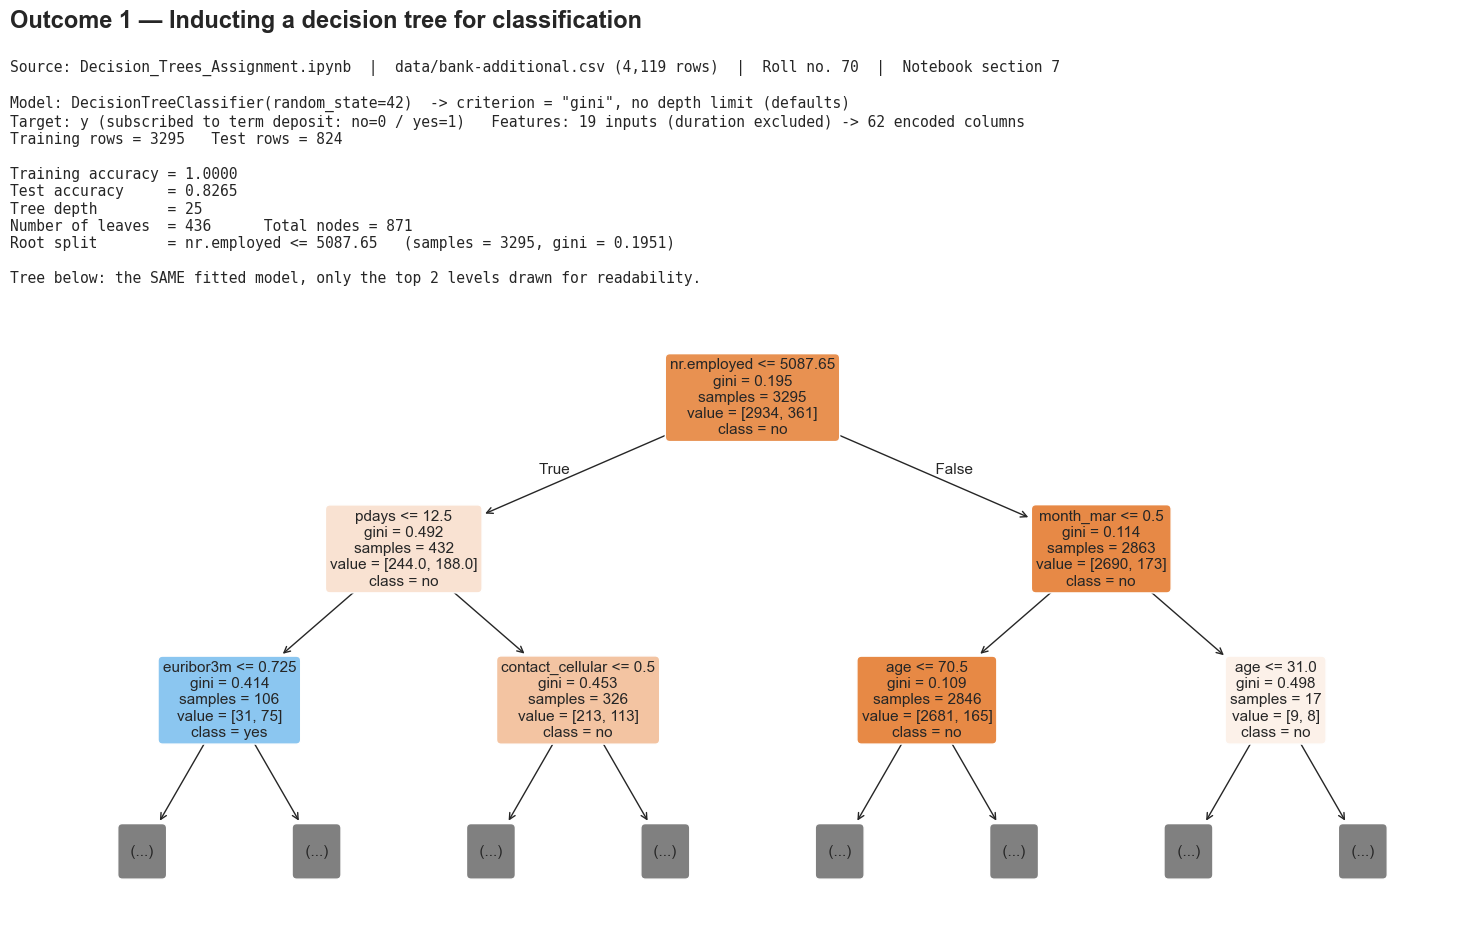

saved -> evidence\outcome_01_classification.png


In [64]:
root_f, root_t = feature_names[tree_clf.tree_.feature[0]], tree_clf.tree_.threshold[0]
text_1 = f'''Model: DecisionTreeClassifier(random_state=42)  -> criterion = "{tree_clf.criterion}", no depth limit (defaults)
Target: y (subscribed to term deposit: no=0 / yes=1)   Features: 19 inputs (duration excluded) -> {X_train.shape[1]} encoded columns
Training rows = {len(X_train)}   Test rows = {len(X_test)}

Training accuracy = {accuracy_score(y_train, tree_clf.predict(X_train)):.4f}
Test accuracy     = {accuracy_score(y_test, tree_clf.predict(X_test)):.4f}
Tree depth        = {tree_clf.get_depth()}
Number of leaves  = {tree_clf.get_n_leaves()}      Total nodes = {tree_clf.tree_.node_count}
Root split        = {root_f} <= {root_t:.2f}   (samples = {tree_clf.tree_.n_node_samples[0]}, gini = {tree_clf.tree_.impurity[0]:.4f})

Tree below: the SAME fitted model, only the top 2 levels drawn for readability.'''

save_evidence("outcome_01_classification.png", "Outcome 1 — Inducting a decision tree for classification", "7",
              text_1, lambda ax: plot_tree(tree_clf, max_depth=2, feature_names=feature_names, class_names=CLASS_NAMES,
                                           filled=True, rounded=True, fontsize=11, ax=ax), plot_height=6.5)

### Outcome 2 — Attribute selection measures (classification)

In [65]:
top_root = root_search.sort_values("gini_decrease", ascending=False).head(6)[
    ["gini_threshold", "gini_decrease", "ig_threshold", "information_gain"]].astype(float).round(5)
crit_table = criterion_comparison[["Criterion", "max_depth", "Root split", "Depth", "Leaves", "Test Acc", "F1"]].round(4)
text_2 = f'''Criterion actually used by the baseline model: criterion="{tree_clf.criterion}" (sklearn default = Gini, NOT information gain)

Root node (training set): {n_no} "no", {n_yes} "yes"   p(no) = {p_no:.4f}, p(yes) = {p_yes:.4f}
  Gini     = 1 - (p_no^2 + p_yes^2)                   = {gini_impurity(y_train_arr):.4f}   (sklearn root gini = {tree_clf.tree_.impurity[0]:.4f})
  Entropy  = -(p_no*log2 p_no + p_yes*log2 p_yes)      = {entropy(y_train_arr):.4f} bits

My search over all {X_train.shape[1]} features x all thresholds (top 6 by Gini decrease):
{top_root.to_string()}

Best by Gini decrease   : {best_gini_feature} <= {root_search.loc[best_gini_feature, "gini_threshold"]:.2f}  | sklearn root (gini)   : {feature_names[tree_clf.tree_.feature[0]]} <= {tree_clf.tree_.threshold[0]:.2f}
Best by information gain: {best_ig_feature} <= {root_search.loc[best_ig_feature, "ig_threshold"]:.2f}  | sklearn root (entropy): {feature_names[tree_entropy.tree_.feature[0]]} <= {tree_entropy.tree_.threshold[0]:.2f}

Comparison of criteria (same data, same settings):
{crit_table.to_string(index=False)}'''

save_evidence("outcome_02_attribute_selection.png", "Outcome 2 — Attribute selection measures: Gini, entropy, information gain", "8", text_2)

<Figure size 1500x588.4 with 0 Axes>

saved -> evidence\outcome_02_attribute_selection.png


### Outcome 3 — Prediction

In [66]:
prediction_lines = "\n".join(
    f"Sample {k} (CSV row {X_test.index[pos]:>4}):  Actual = {CLASS_NAMES[y_test_arr[pos]]:3s} | Predicted = "
    f"{CLASS_NAMES[y_pred[pos]]:3s} | P(yes) = {y_proba_yes[pos]:.2f} | {'correct' if y_pred[pos] == y_test_arr[pos] else 'WRONG'}"
    for k, pos in enumerate(sample_positions, start=1))
text_3 = f'''Model: baseline classification tree (Outcome 1) applied to UNSEEN test clients with predict() and predict_proba()

{prediction_lines}

Input values of these clients (selected columns) and the model output:
{examples.to_string()}

Decision path followed by Sample 6 (how the tree reached its prediction):
{captured(explain_prediction, tree_clf, X_test, sample_positions[5])}'''

save_evidence("outcome_03_prediction.png", "Outcome 3 — Predicting the outcome variable with the tree", "9", text_3)

<Figure size 1500x695.2 with 0 Axes>

saved -> evidence\outcome_03_prediction.png


### Outcome 4 — Classification evaluation

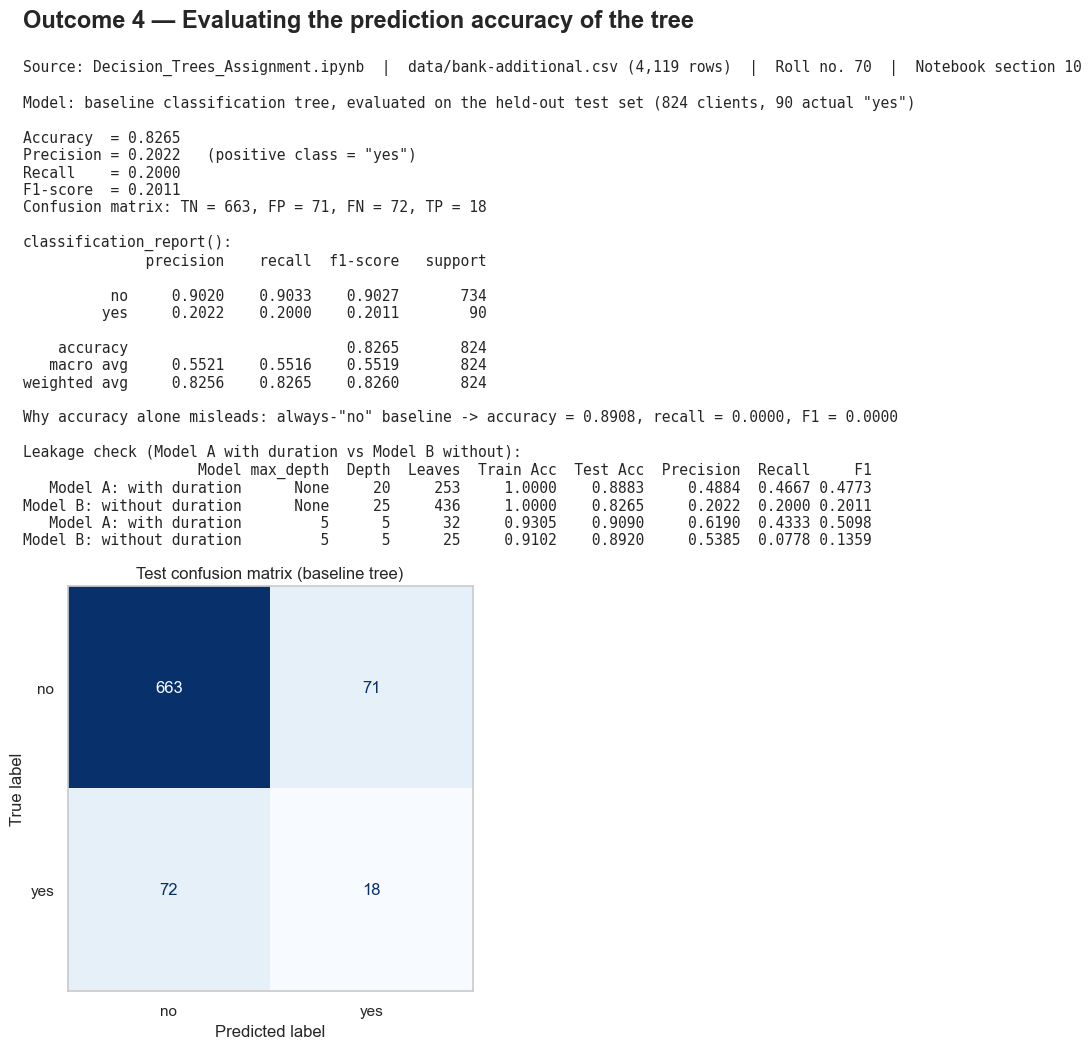

saved -> evidence\outcome_04_accuracy.png


In [67]:
text_4 = f'''Model: baseline classification tree, evaluated on the held-out test set ({len(y_test)} clients, {int(y_test.sum())} actual "yes")

Accuracy  = {test_accuracy:.4f}
Precision = {test_precision:.4f}   (positive class = "yes")
Recall    = {test_recall:.4f}
F1-score  = {test_f1:.4f}
Confusion matrix: TN = {tn}, FP = {fp}, FN = {fn}, TP = {tp}

classification_report():
{classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4)}
Why accuracy alone misleads: always-"no" baseline -> accuracy = {accuracy_score(y_test, majority_pred):.4f}, recall = {recall_score(y_test, majority_pred):.4f}, F1 = {f1_score(y_test, majority_pred):.4f}

Leakage check (Model A with duration vs Model B without):
{leakage_comparison.round(4).to_string(index=False)}'''


def draw_cm(ax):
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.grid(False)
    ax.set_anchor("W")
    ax.set_title("Test confusion matrix (baseline tree)")


save_evidence("outcome_04_accuracy.png", "Outcome 4 — Evaluating the prediction accuracy of the tree", "10",
              text_4, draw_cm, plot_height=4.5)

### Outcome 5 — Regression tree induction

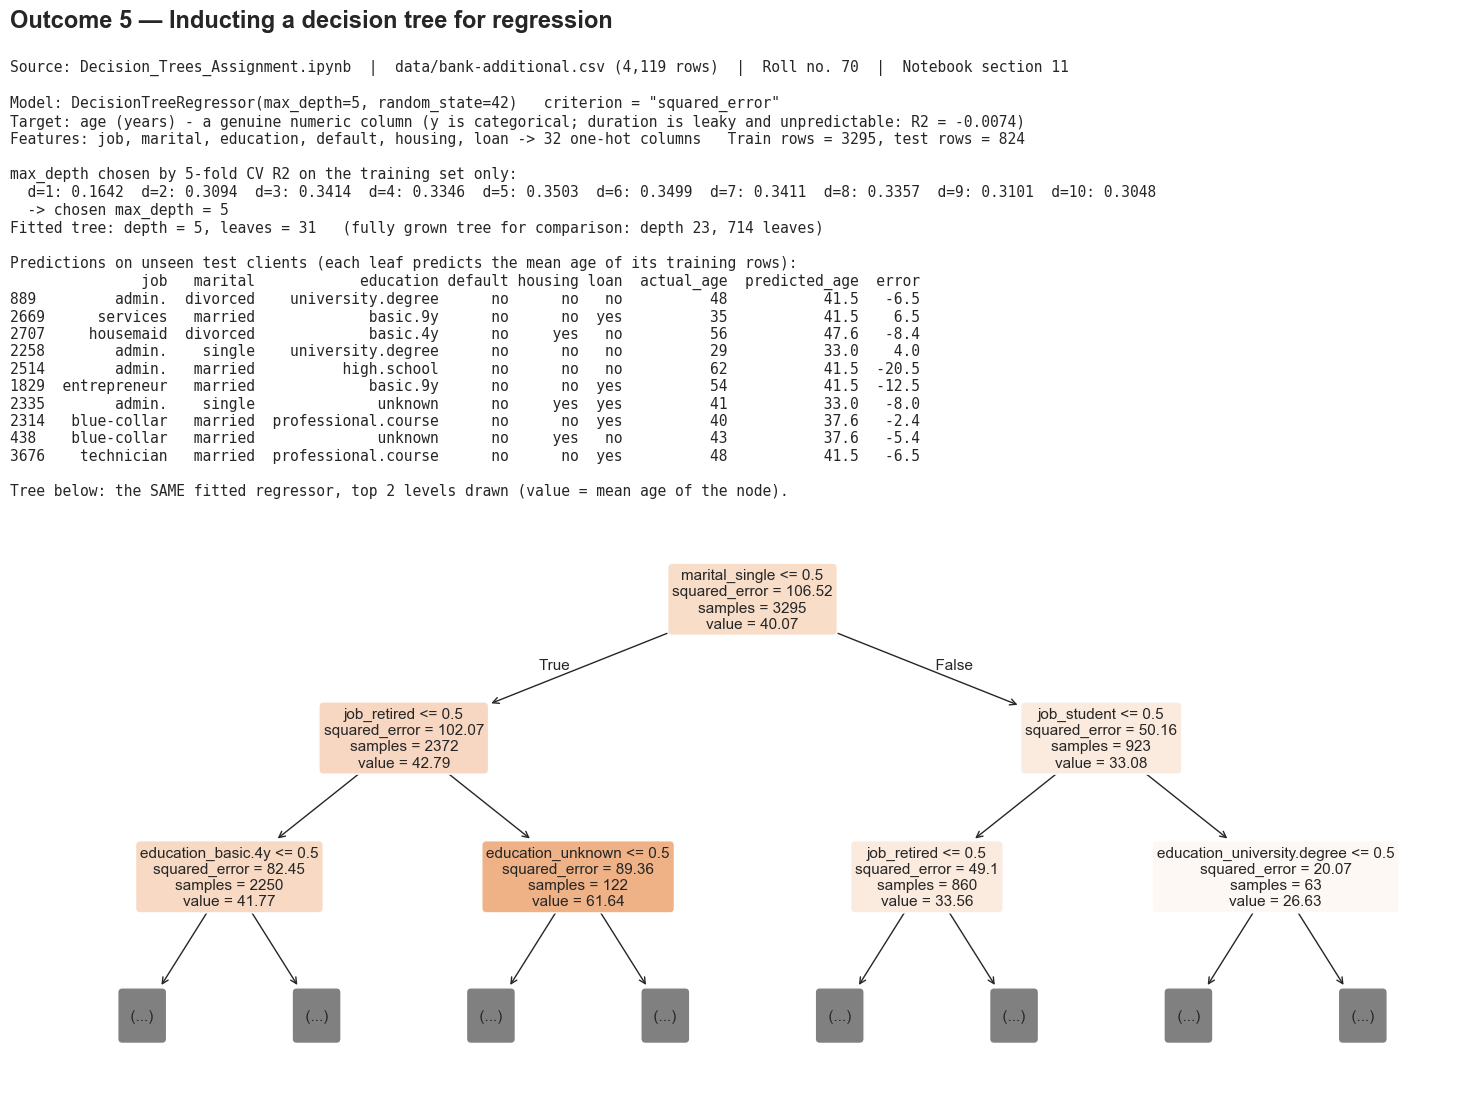

saved -> evidence\outcome_05_regression.png


In [68]:
cv_line = "  ".join(f"d={d}: {s:.4f}" for d, s in depth_scores.items())
text_5 = f'''Model: DecisionTreeRegressor(max_depth={best_reg_depth}, random_state=42)   criterion = "{reg_tree.criterion}"
Target: age (years) - a genuine numeric column (y is categorical; duration is leaky and unpredictable: R2 = {r2_score(X_test_raw["duration"], duration_tree.predict(Xd_test)):.4f})
Features: {", ".join(reg_features)} -> {Xr_train.shape[1]} one-hot columns   Train rows = {len(Xr_train)}, test rows = {len(Xr_test)}

max_depth chosen by 5-fold CV R2 on the training set only:
  {cv_line}
  -> chosen max_depth = {best_reg_depth}
Fitted tree: depth = {reg_tree.get_depth()}, leaves = {reg_tree.get_n_leaves()}   (fully grown tree for comparison: depth {reg_tree_full.get_depth()}, {reg_tree_full.get_n_leaves()} leaves)

Predictions on unseen test clients (each leaf predicts the mean age of its training rows):
{reg_examples.to_string()}

Tree below: the SAME fitted regressor, top 2 levels drawn (value = mean age of the node).'''

save_evidence("outcome_05_regression.png", "Outcome 5 — Inducting a decision tree for regression", "11", text_5,
              lambda ax: plot_tree(reg_tree, max_depth=2, feature_names=reg_feature_names, filled=True, rounded=True,
                                   fontsize=11, precision=2, ax=ax), plot_height=6)

### Outcome 6 — Attribute selection for regression

In [69]:
lc, rc = reg_tree.tree_.children_left[0], reg_tree.tree_.children_right[0]
sk_child_mse = (reg_tree.tree_.n_node_samples[lc] * reg_tree.tree_.impurity[lc]
                + reg_tree.tree_.n_node_samples[rc] * reg_tree.tree_.impurity[rc]) / len(yr_train_arr)
text_6 = f'''Criterion actually used: criterion="{reg_tree.criterion}" (MSE = variance of the node; entropy/Gini do NOT apply to a numeric target)
Split quality = MSE(parent) - [ |L|/|D| * MSE(L) + |R|/|D| * MSE(R) ]   (variance reduction = reduction in squared prediction error)

Root node: {len(yr_train_arr)} rows, mean age = {yr_train_arr.mean():.3f}, MSE = variance = {parent_mse:.3f}  (sklearn root impurity = {reg_tree.tree_.impurity[0]:.3f})

My search over all candidate splits (top 6 by MSE reduction):
{regression_split_search.head(6).round(3).to_string(index=False)}

Best split by my search : {regression_split_search.iloc[0]["split"]}   weighted child MSE = {regression_split_search.iloc[0]["weighted_child_MSE"]:.3f}
Root split by sklearn   : {reg_feature_names[reg_tree.tree_.feature[0]]} <= {reg_tree.tree_.threshold[0]:.2f}   weighted child MSE = {sk_child_mse:.3f}

Effect of changing the regression criterion (max_depth={best_reg_depth}):
{regression_criterion_comparison.round(4).to_string(index=False)}'''

save_evidence("outcome_06_regression_selection.png", "Outcome 6 — Attribute selection for regression: MSE / variance reduction", "12", text_6)

<Figure size 1500x535 with 0 Axes>

saved -> evidence\outcome_06_regression_selection.png


### Outcome 7 — R² and RMSE

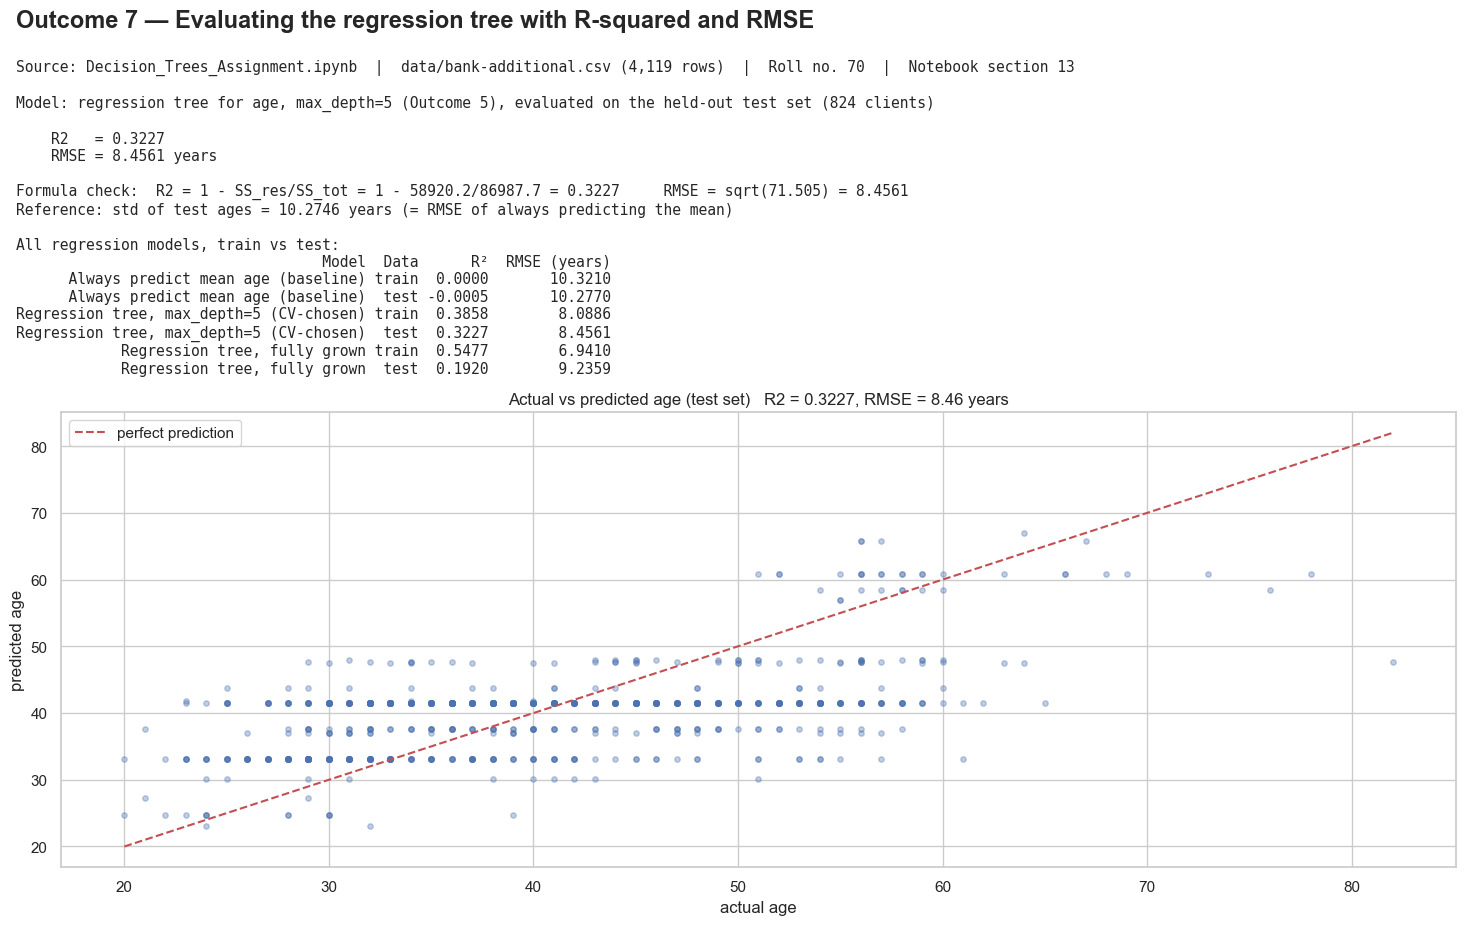

saved -> evidence\outcome_07_r2_rmse.png


In [70]:
reg_r2 = r2_score(yr_test, yr_pred)
reg_rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))
text_7 = f'''Model: regression tree for age, max_depth={best_reg_depth} (Outcome 5), evaluated on the held-out test set ({len(yr_test)} clients)

    R2   = {reg_r2:.4f}
    RMSE = {reg_rmse:.4f} years

Formula check:  R2 = 1 - SS_res/SS_tot = 1 - {ss_res:.1f}/{ss_tot:.1f} = {1 - ss_res / ss_tot:.4f}     RMSE = sqrt({np.mean(residuals ** 2):.3f}) = {np.sqrt(np.mean(residuals ** 2)):.4f}
Reference: std of test ages = {yr_test.std(ddof=0):.4f} years (= RMSE of always predicting the mean)

All regression models, train vs test:
{regression_evaluation.round(4).to_string(index=False)}'''


def draw_actual_vs_pred(ax):
    ax.scatter(yr_test, yr_pred, alpha=0.35, s=15)
    lims = [yr_test.min(), yr_test.max()]
    ax.plot(lims, lims, "r--", label="perfect prediction")
    ax.set_xlabel("actual age")
    ax.set_ylabel("predicted age")
    ax.set_title(f"Actual vs predicted age (test set)   R2 = {reg_r2:.4f}, RMSE = {reg_rmse:.2f} years")
    ax.legend()


save_evidence("outcome_07_r2_rmse.png", "Outcome 7 — Evaluating the regression tree with R-squared and RMSE", "13",
              text_7, draw_actual_vs_pred, plot_height=5)

### Outcome 8 — Model tree (piece-wise models)

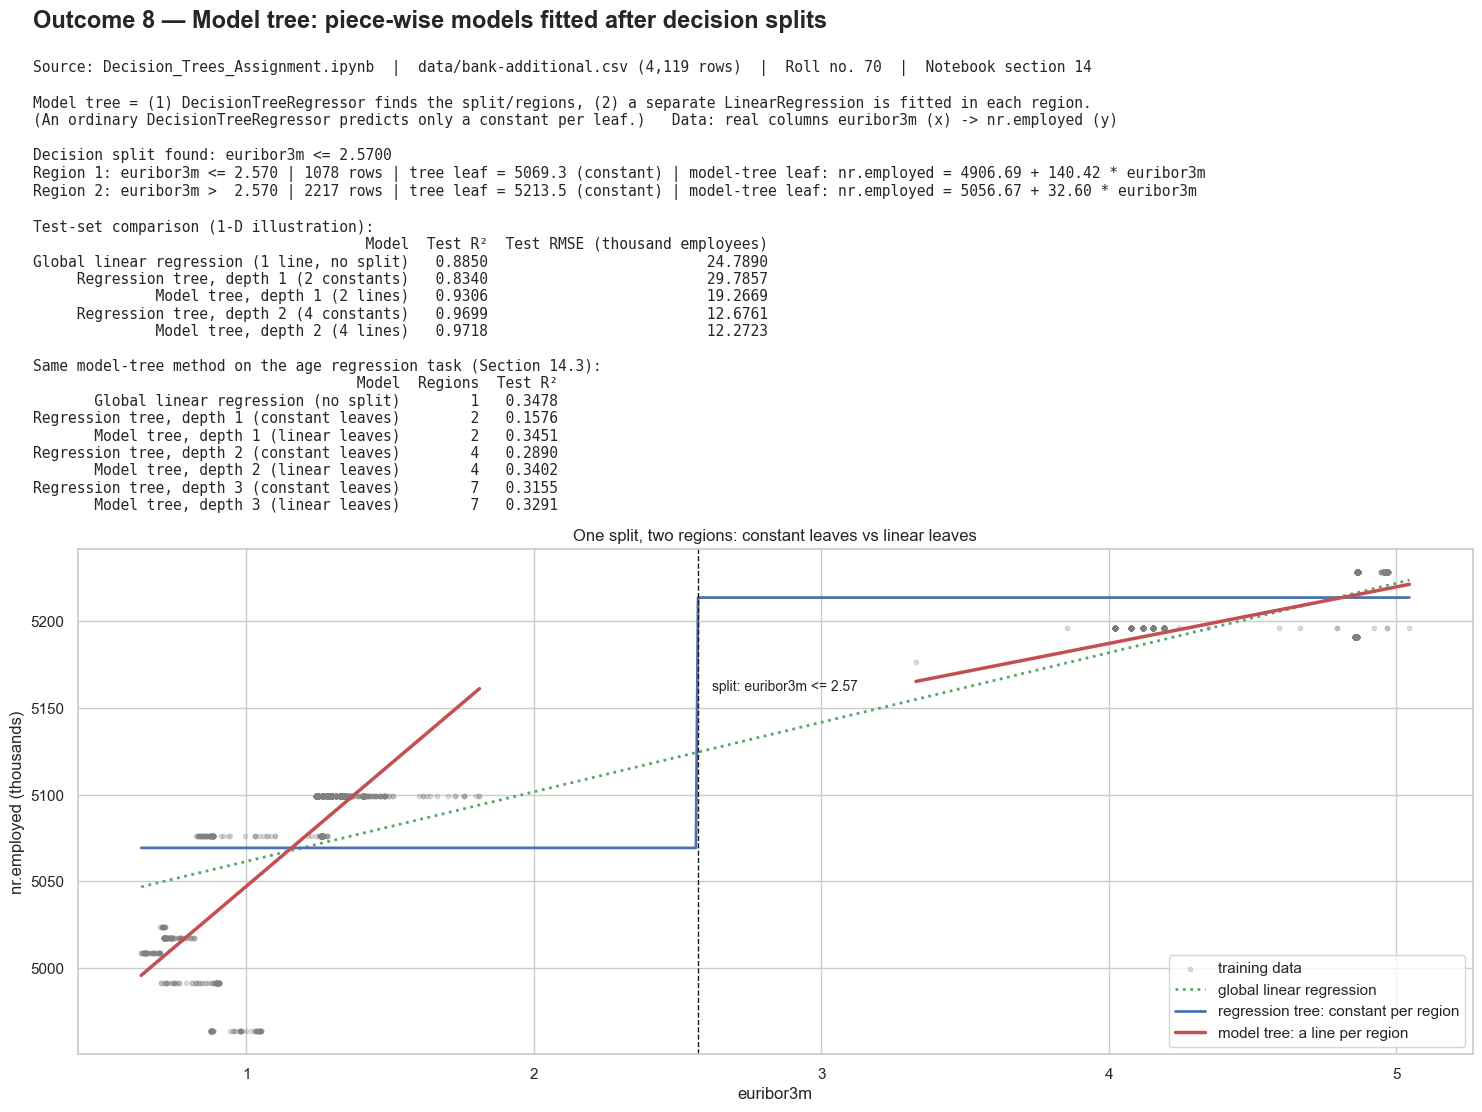

saved -> evidence\outcome_08_piecewise.png


In [71]:
pw_threshold = pw_splitter.tree_.threshold[0]
train_leaf = pw_splitter.apply(Xpw_train)
region_lines = []
for leaf, lm in pw_leaf_models.items():
    in_region = train_leaf == leaf
    name = (f"Region 1: euribor3m <= {pw_threshold:.3f}" if leaf == pw_splitter.tree_.children_left[0]
            else f"Region 2: euribor3m >  {pw_threshold:.3f}")
    region_lines.append(f"{name} | {in_region.sum():4d} rows | tree leaf = {ypw_train[in_region].mean():.1f} (constant) | "
                        f"model-tree leaf: nr.employed = {lm.intercept_:.2f} + {lm.coef_[0]:.2f} * euribor3m")
nl = "\n"
text_8 = f'''Model tree = (1) DecisionTreeRegressor finds the split/regions, (2) a separate LinearRegression is fitted in each region.
(An ordinary DecisionTreeRegressor predicts only a constant per leaf.)   Data: real columns euribor3m (x) -> nr.employed (y)

Decision split found: euribor3m <= {pw_threshold:.4f}
{nl.join(region_lines)}

Test-set comparison (1-D illustration):
{piecewise_1d.round(4).to_string(index=False)}

Same model-tree method on the age regression task (Section 14.3):
{model_tree_age.round(4).to_string(index=False)}'''


def draw_piecewise(ax):
    grid = pd.DataFrame({"euribor3m": np.linspace(X_pw["euribor3m"].min(), X_pw["euribor3m"].max(), 600)})
    ax.scatter(Xpw_train["euribor3m"], ypw_train, s=10, alpha=0.25, color="grey", label="training data")
    ax.plot(grid["euribor3m"], global_line.predict(grid), "g:", lw=2, label="global linear regression")
    ax.plot(grid["euribor3m"], step_tree.predict(grid), "b-", lw=2, label="regression tree: constant per region")
    for k, (leaf, lm) in enumerate(pw_leaf_models.items()):
        x_region = Xpw_train["euribor3m"][train_leaf == leaf]
        x_line = pd.DataFrame({"euribor3m": np.linspace(x_region.min(), x_region.max(), 100)})
        ax.plot(x_line["euribor3m"], lm.predict(x_line), "r-", lw=2.5,
                label="model tree: a line per region" if k == 0 else None)
    ax.axvline(pw_threshold, color="k", ls="--", lw=1)
    ax.text(pw_threshold + 0.05, 5160, f"split: euribor3m <= {pw_threshold:.2f}", fontsize=10)
    ax.set_xlabel("euribor3m")
    ax.set_ylabel("nr.employed (thousands)")
    ax.set_title("One split, two regions: constant leaves vs linear leaves")
    ax.legend(loc="lower right")


save_evidence("outcome_08_piecewise.png", "Outcome 8 — Model tree: piece-wise models fitted after decision splits", "14",
              text_8, draw_piecewise, plot_height=5.5)

### Outcome 9 — Pruning

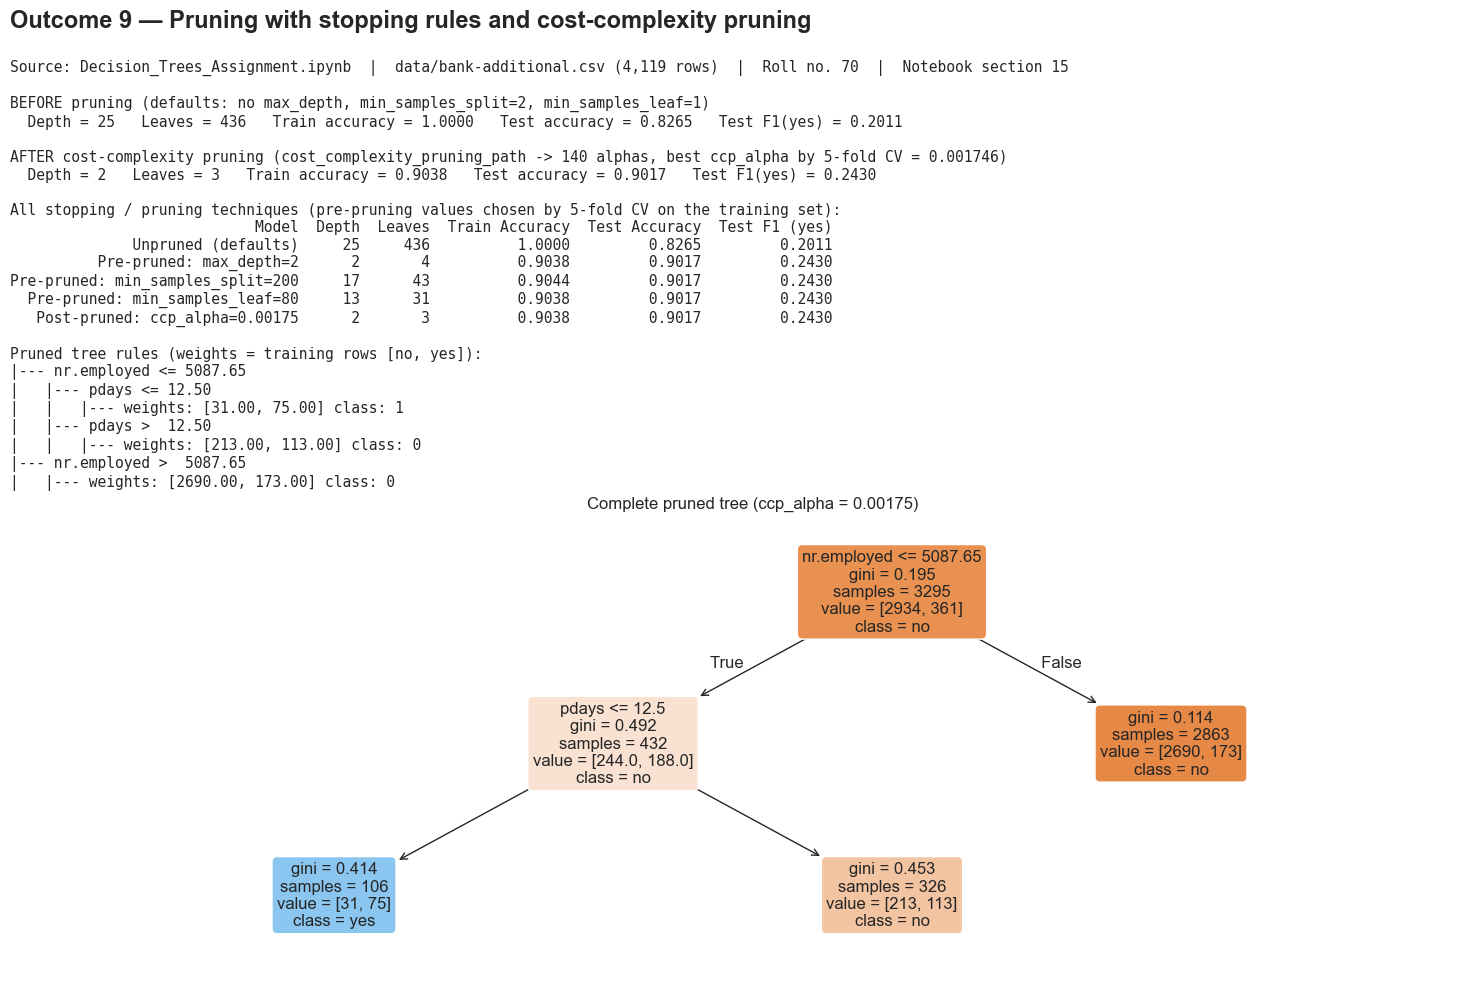

saved -> evidence\outcome_09_pruning.png


In [72]:
def acc_pair(model):
    return accuracy_score(y_train, model.predict(X_train)), accuracy_score(y_test, model.predict(X_test))


u_tr, u_te = acc_pair(unpruned)
p_tr, p_te = acc_pair(pruned_clf)
text_9 = f'''BEFORE pruning (defaults: no max_depth, min_samples_split=2, min_samples_leaf=1)
  Depth = {unpruned.get_depth()}   Leaves = {unpruned.get_n_leaves()}   Train accuracy = {u_tr:.4f}   Test accuracy = {u_te:.4f}   Test F1(yes) = {f1_score(y_test, unpruned.predict(X_test)):.4f}

AFTER cost-complexity pruning (cost_complexity_pruning_path -> {len(ccp_alphas)} alphas, best ccp_alpha by 5-fold CV = {best_alpha:.6f})
  Depth = {pruned_clf.get_depth()}   Leaves = {pruned_clf.get_n_leaves()}   Train accuracy = {p_tr:.4f}   Test accuracy = {p_te:.4f}   Test F1(yes) = {f1_score(y_test, pruned_clf.predict(X_test)):.4f}

All stopping / pruning techniques (pre-pruning values chosen by 5-fold CV on the training set):
{pruning_table.round(4).to_string(index=False)}

Pruned tree rules (weights = training rows [no, yes]):
{export_text(pruned_clf, feature_names=feature_names, show_weights=True)}'''


def draw_pruned(ax):
    plot_tree(pruned_clf, feature_names=feature_names, class_names=CLASS_NAMES, filled=True, rounded=True,
              fontsize=12, ax=ax)
    ax.set_title(f"Complete pruned tree (ccp_alpha = {best_alpha:.5f})")


save_evidence("outcome_09_pruning.png", "Outcome 9 — Pruning with stopping rules and cost-complexity pruning", "15",
              text_9, draw_pruned, plot_height=5)

### One-page mapping (generated from the results above)

The table below is written to `One_Page_Mapping.md` and rendered as a one-page `One_Page_Mapping.pdf`. All values are read from the variables computed in this notebook.

In [73]:
from matplotlib.backends.backend_pdf import PdfPages

mapping_rows = [
    ("1", "Classification tree induction",
     f"DecisionTreeClassifier (criterion={tree_clf.criterion}) trained on {len(X_train)} clients; depth {tree_clf.get_depth()}, "
     f"{tree_clf.get_n_leaves()} leaves; train acc {accuracy_score(y_train, tree_clf.predict(X_train)):.4f}, "
     f"test acc {accuracy_score(y_test, tree_clf.predict(X_test)):.4f}; root split {root_f} <= {root_t:.2f}; tree diagram",
     "outcome_01_classification.png"),
    ("2", "Attribute selection (classification)",
     f"Root Gini {gini_impurity(y_train_arr):.4f}, entropy {entropy(y_train_arr):.4f} bits; search of all {X_train.shape[1]} features: "
     f"best Gini decrease {root_search['gini_decrease'].max():.4f}, best information gain {root_search['information_gain'].max():.4f} "
     f"({best_gini_feature}), same root as sklearn for gini and entropy; gini/entropy/log_loss compared",
     "outcome_02_attribute_selection.png"),
    ("3", "Prediction",
     f"predict()/predict_proba() on {len(sample_positions)} unseen test clients: "
     f"{sum(y_pred[p] == y_test_arr[p] for p in sample_positions)} correct, "
     f"{sum(y_pred[p] != y_test_arr[p] for p in sample_positions)} wrong; decision path of one client traced node by node",
     "outcome_03_prediction.png"),
    ("4", "Classification evaluation",
     f"Accuracy {test_accuracy:.4f}, precision {test_precision:.4f}, recall {test_recall:.4f}, F1 {test_f1:.4f}; "
     f"confusion matrix TN {tn} / FP {fp} / FN {fn} / TP {tp}; always-'no' baseline accuracy "
     f"{accuracy_score(y_test, majority_pred):.4f} with recall 0",
     "outcome_04_accuracy.png"),
    ("5", "Regression tree induction",
     f"DecisionTreeRegressor predicting age from client profile; max_depth={best_reg_depth} chosen by 5-fold CV; "
     f"{reg_tree.get_n_leaves()} leaves; prediction table and tree diagram",
     "outcome_05_regression.png"),
    ("6", "Attribute selection (regression)",
     f"criterion={reg_tree.criterion}; root MSE = variance = {parent_mse:.2f}; best split "
     f"{regression_split_search.iloc[0]['split']} (child MSE {regression_split_search.iloc[0]['weighted_child_MSE']:.2f}), "
     f"same as sklearn root; 4 criteria compared",
     "outcome_06_regression_selection.png"),
    ("7", "R-squared and RMSE",
     f"Test R2 = {reg_r2:.4f}, RMSE = {reg_rmse:.2f} years (mean-only baseline RMSE {yr_test.std(ddof=0):.2f}); "
     f"both verified from their formulas; fully grown tree test R2 {r2_score(yr_test, reg_tree_full.predict(Xr_test)):.4f}",
     "outcome_07_r2_rmse.png"),
    ("8", "Model tree (piece-wise models)",
     f"Split euribor3m <= {pw_threshold:.2f} + one LinearRegression per region; test R2 "
     f"{piecewise_1d.loc[2, 'Test R²']:.3f} vs {piecewise_1d.loc[0, 'Test R²']:.3f} (global line) vs "
     f"{piecewise_1d.loc[1, 'Test R²']:.3f} (constant leaves); age task {model_tree_age.loc[2, 'Test R²']:.3f} vs "
     f"{model_tree_age.loc[1, 'Test R²']:.3f}",
     "outcome_08_piecewise.png"),
    ("9", "Pruning",
     f"Before: depth {unpruned.get_depth()}, {unpruned.get_n_leaves()} leaves, test acc {u_te:.4f}. "
     f"After ccp_alpha={best_alpha:.5f}: depth {pruned_clf.get_depth()}, {pruned_clf.get_n_leaves()} leaves, test acc {p_te:.4f}; "
     f"max_depth / min_samples_split / min_samples_leaf (CV-tuned) also compared",
     "outcome_09_pruning.png"),
]

header = ("# One-Page Mapping: Nine Learning Outcomes → Evidence\n\n"
          "**Assignment 3 (Infosys Springboard — Decision Trees using Python) · Roll no. 70**  \n"
          "Notebook: `Decision_Trees_Assignment.ipynb` · Data: `data/bank-additional.csv` (4,119 clients, UCI Bank Marketing) · "
          "80/20 split, `random_state=42`\n\n")
table = "| Outcome | Evidence from my project (actual outputs) | Screenshot |\n|---|---|---|\n"
table += "\n".join(f"| {n}. {name} | {evidence} | `evidence/{shot}` |" for n, name, evidence, shot in mapping_rows)
footer = ("\n\nAll values above are generated by Section 20 of the notebook from the models trained in Sections 7–15. "
          "Classification uses Model B (without the leaky `duration` column); regression predicts `age`.\n")
with open("One_Page_Mapping.md", "w", encoding="utf-8") as f:
    f.write(header + table + footer)

# One-page A4 landscape PDF of the same table
with PdfPages("One_Page_Mapping.pdf") as pdf:
    fig = plt.figure(figsize=(11.69, 8.27))
    fig.text(0.03, 0.955, "One-Page Mapping: Nine Learning Outcomes → Evidence", fontsize=15, weight="bold")
    fig.text(0.03, 0.925, "Assignment 3 (Infosys Springboard — Decision Trees using Python) · Roll no. 70 · "
             "Notebook: Decision_Trees_Assignment.ipynb · Data: data/bank-additional.csv (4,119 clients)", fontsize=9)
    cell_text = [[f"{n}. {name}", textwrap.fill(evidence, 95), shot] for n, name, evidence, shot in mapping_rows]
    ax = fig.add_axes([0.03, 0.05, 0.94, 0.85])
    ax.axis("off")
    tbl = ax.table(cellText=cell_text, colLabels=["Outcome", "Evidence from my project (actual outputs)", "Screenshot (evidence/)"],
                   colWidths=[0.17, 0.60, 0.23], loc="upper center", cellLoc="left")
    tbl.auto_set_font_size(False)
    tbl.set_fontsize(7.6)
    row_lines = {r: max(tbl[r, c].get_text().get_text().count("\n") + 1 for c in range(3))
                 for r in range(len(cell_text) + 1)}
    for (r, c), cell in tbl.get_celld().items():
        cell.set_height(0.028 if r == 0 else 0.022 * row_lines[r] + 0.012)
        cell.get_text().set_va("center")
        if r == 0:
            cell.set_facecolor("#dfe7f2")
            cell.get_text().set_weight("bold")
    fig.text(0.03, 0.025, "All values are generated by Section 20 of the notebook from the models trained in Sections 7–15.",
             fontsize=8, style="italic")
    pdf.savefig(fig)
    plt.close(fig)

print(open("One_Page_Mapping.md", encoding="utf-8").read())
print("saved -> One_Page_Mapping.md, One_Page_Mapping.pdf")
print("evidence files:", sorted(os.listdir(EVIDENCE_DIR)))

# One-Page Mapping: Nine Learning Outcomes → Evidence

**Assignment 3 (Infosys Springboard — Decision Trees using Python) · Roll no. 70**  
Notebook: `Decision_Trees_Assignment.ipynb` · Data: `data/bank-additional.csv` (4,119 clients, UCI Bank Marketing) · 80/20 split, `random_state=42`

| Outcome | Evidence from my project (actual outputs) | Screenshot |
|---|---|---|
| 1. Classification tree induction | DecisionTreeClassifier (criterion=gini) trained on 3295 clients; depth 25, 436 leaves; train acc 1.0000, test acc 0.8265; root split nr.employed <= 5087.65; tree diagram | `evidence/outcome_01_classification.png` |
| 2. Attribute selection (classification) | Root Gini 0.1951, entropy 0.4986 bits; search of all 62 features: best Gini decrease 0.0320, best information gain 0.0831 (nr.employed), same root as sklearn for gini and entropy; gini/entropy/log_loss compared | `evidence/outcome_02_attribute_selection.png` |
| 3. Prediction | predict()/predict_proba() on 8 unseen test clients: 7